# Hotel Booking Cancellation Prediction with Machine Learning

**Tugas Besar — Machine Learning untuk Data Science**

**Dataset utama:** `data_hotel_booking_demand.csv` (data reservasi sebuah hotel di Portugal)

**Dataset pendukung (Kaggle):**

| No | File | Sumber | Kegunaan dalam project |
|---|---|---|---|
| 1 | `hotel_bookings.csv` | [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) (Antonio, Almeida & Nunes, 2019, *Data in Brief*, 22, 41–49) | Sumber data yang sama dengan dataset utama dan memiliki kolom tambahan. Dipakai untuk (1) menghitung **harga kamar rata-rata (ADR)** dan **lama menginap** sebagai dasar biaya kesalahan prediksi, dan (2) mengukur **seberapa besar fitur yang tidak tersedia** (misalnya *lead time*) memengaruhi performa model |
| 2 | `Hotel Reservations.csv` | [Hotel Reservations Dataset](https://www.kaggle.com/datasets/ahsan81/hotel-reservations-classification-dataset) | Data reservasi dari **hotel lain** dengan target pembatalan. Dipakai untuk **memvalidasi** apakah pola pembatalan yang ditemukan di EDA juga berlaku di hotel lain |
| 3 | `continents2.csv` | Country Mapping – ISO, Continent, Region (Kaggle) | Tabel pemetaan kode negara ISO ke benua dan sub-region. Dipakai untuk **feature engineering**: meringkas `country` (162 negara) menjadi `sub_region` |

---

### Daftar Isi (mengikuti Roadmap)

| No | Stage | Isi |
|---|---|---|
| 1 | **Business Problem Understanding** | Stakeholder, konteks, problem statement, goals, analytic approach, metric evaluation |
| 2 | **Data Understanding** | Sumber data, struktur data, arti setiap kolom, kaitan dengan bisnis, dataset pendukung |
| 3 | **Data Cleaning** | Missing value, duplikat, tipe data, data anomali, outlier |
| 4 | **Exploratory Data Analysis** | Hubungan fitur dengan target pembatalan |
| 5 | **Data Preparation** | Feature selection, feature engineering, encoding, scaling, split data |
| 6 | **Experiment Planning** | Rancangan percobaan pemodelan |
| 7 | **Modeling** | Benchmarking model, penanganan imbalance, hyperparameter tuning, threshold tuning |
| 8 | **Evaluation** | Evaluasi akhir di data test, analisis biaya, limitasi model |
| 9 | **Model Explanation** | Feature importance, SHAP |
| 10 | **Conclusion & Recommendation** | Kesimpulan dan rekomendasi bisnis |

# 1. Business Problem Understanding

### 1.1 Context

Hotel yang menjadi objek analisis adalah sebuah hotel di Portugal. Setiap reservasi yang masuk tercatat di *Property Management System* (PMS), mulai dari asal negara tamu, segmen pasar (online travel agent, offline travel agent, group, direct, corporate), jenis deposit, jenis kamar, sampai jumlah permintaan khusus.

Masalah besar di industri perhotelan adalah **pembatalan reservasi (*booking cancellation*)**. Pada data ini, sekitar **37% reservasi berakhir dibatalkan**. Kamar yang dibatalkan mendadak sulit dijual kembali, sehingga hotel kehilangan pendapatan dan perencanaan okupansi, staf, serta stok menjadi tidak akurat.

### 1.2 Stakeholder

| Stakeholder | Peran | Bagaimana memakai model |
|---|---|---|
| **Revenue Management** (pengguna utama) | Mengatur harga, kuota kamar, dan kebijakan *overbooking* | Memakai probabilitas pembatalan untuk menentukan berapa kamar yang aman dijual ulang / di-*overbook* |
| **Reservation / Front Office** | Mengelola reservasi dan komunikasi dengan tamu | Menghubungi tamu yang berisiko batal (konfirmasi ulang, tawaran khusus) |
| **Manajemen Hotel** | Pengambil keputusan kebijakan | Menentukan kebijakan deposit dan kerja sama dengan agen perjalanan |

**Kapan model dipakai?** Model dijalankan secara *batch* setiap hari untuk semua reservasi aktif yang belum check-in. Hasilnya berupa daftar reservasi yang berisiko tinggi dibatalkan.

### 1.3 Problem Statement

Saat ini hotel **tidak bisa membedakan reservasi yang kemungkinan besar dibatalkan dari reservasi yang kemungkinan besar datang**. Akibatnya:

1. **Jika hotel tidak mengantisipasi pembatalan**, kamar yang dibatalkan menjadi kamar kosong. Pendapatan dari kamar tersebut hilang. Dengan tingkat pembatalan ±37%, kerugiannya sangat besar.
2. **Jika hotel melakukan *overbooking* tanpa dasar yang jelas**, tamu yang ternyata datang bisa tidak mendapat kamar dan harus dipindahkan ke hotel lain (*walking a guest*), yang menimbulkan biaya relokasi, kompensasi, dan kerusakan reputasi.

### 1.4 Goals

Hotel membutuhkan alat untuk **memprediksi kemungkinan setiap reservasi dibatalkan**, sehingga:

- Hotel bisa **mengantisipasi kamar kosong** dengan menjual ulang kamar / *overbooking* secara terukur pada reservasi berisiko tinggi.
- Tim reservasi bisa **melakukan tindakan pencegahan** (konfirmasi ulang, penawaran fasilitas) pada tamu berisiko tinggi.
- Hotel memahami **faktor apa saja yang memengaruhi pembatalan**, sebagai dasar kebijakan (misalnya kebijakan deposit dan kerja sama dengan agen).

**Target terukur (dari Project Charter):** model mencapai **F2-score ≥ 0,75** dan **recall kelas batal ≥ 80%** pada data test, serta **total biaya lebih rendah** dibanding skenario tanpa model.

### 1.5 Analytic Approach

Kita akan menganalisis pola data untuk menemukan karakteristik reservasi yang dibatalkan dan yang tidak. Lalu kita membangun **model klasifikasi biner** yang memprediksi probabilitas sebuah reservasi dibatalkan (`is_canceled = 1`) atau tidak (`is_canceled = 0`).

### 1.6 Metric Evaluation

| | **Prediksi: Tidak Batal (0)** | **Prediksi: Batal (1)** |
|---|---|---|
| **Aktual: Tidak Batal (0)** | True Negative (TN) | **False Positive (FP)** |
| **Aktual: Batal (1)** | **False Negative (FN)** | True Positive (TP) |

- **False Positive (FP)**: model memprediksi batal, ternyata tamu datang. Jika kamarnya sudah dijual ulang, hotel harus merelokasi tamu → **biaya relokasi/kompensasi ≈ 1 malam ADR**.
- **False Negative (FN)**: model memprediksi tidak batal, ternyata dibatalkan. Hotel tidak sempat menjual ulang kamar → **pendapatan 1 reservasi hilang ≈ ADR × rata-rata lama menginap**.

Dengan data pendukung Kaggle (dihitung di bagian Data Understanding), biaya FN sekitar **3–4 kali** biaya FP. Karena **FN lebih mahal**, kita lebih mengutamakan **recall** tetapi tetap tidak ingin precision terlalu rendah. Karena itu:

- **Metrik utama untuk memilih model:** **F2-score**, yaitu F-beta dengan β = 2, yang memberi bobot recall lebih besar daripada precision.
- **Metrik bisnis:** **total biaya (Euro)** = jumlah FP × biaya FP + jumlah FN × biaya FN. Metrik ini juga dipakai untuk memilih *threshold* akhir.
- **Metrik pendukung:** recall, precision, ROC AUC, dan PR AUC.

## Import Library

In [1]:
# Library untuk manipulasi data
import pandas as pd  # untuk mengolah data dalam bentuk tabel (DataFrame)
import numpy as np  # untuk perhitungan numerik

# Library untuk visualisasi data
import matplotlib.pyplot as plt  # untuk membuat grafik
import seaborn as sns  # untuk membuat grafik statistik yang lebih rapi

# Library untuk preprocessing data
from sklearn.model_selection import train_test_split  # untuk membagi data train dan test
from sklearn.model_selection import StratifiedKFold  # untuk membagi data menjadi beberapa fold dengan proporsi target yang sama
from sklearn.model_selection import cross_val_score  # untuk menghitung skor cross validation
from sklearn.model_selection import cross_val_predict  # untuk mendapatkan prediksi hasil cross validation
from sklearn.model_selection import RandomizedSearchCV  # untuk hyperparameter tuning secara acak
from sklearn.compose import ColumnTransformer  # untuk menerapkan preprocessing berbeda pada kolom berbeda
from sklearn.pipeline import Pipeline  # untuk menggabungkan preprocessing dan model dalam satu alur
from sklearn.impute import SimpleImputer  # untuk mengisi missing value
from sklearn.preprocessing import OneHotEncoder  # untuk mengubah data kategorikal menjadi angka
from sklearn.preprocessing import RobustScaler  # untuk menyamakan skala data numerik (tahan terhadap outlier)

# Library untuk model machine learning
from sklearn.linear_model import LogisticRegression  # model Logistic Regression
from sklearn.neighbors import KNeighborsClassifier  # model K-Nearest Neighbors
from sklearn.tree import DecisionTreeClassifier  # model Decision Tree
from sklearn.ensemble import RandomForestClassifier  # model Random Forest (ensemble bagging)
from sklearn.ensemble import AdaBoostClassifier  # model AdaBoost (ensemble boosting)
from sklearn.ensemble import GradientBoostingClassifier  # model Gradient Boosting (ensemble boosting)
from sklearn.ensemble import HistGradientBoostingClassifier  # model Gradient Boosting versi cepat (mirip LightGBM)

# Library untuk evaluasi model
from sklearn.metrics import fbeta_score, make_scorer  # untuk menghitung F2-score dan membuat scorer
from sklearn.metrics import recall_score, precision_score  # untuk menghitung recall dan precision
from sklearn.metrics import roc_auc_score, average_precision_score  # untuk menghitung ROC AUC dan PR AUC
from sklearn.metrics import confusion_matrix, classification_report  # untuk confusion matrix dan laporan klasifikasi
from sklearn.metrics import ConfusionMatrixDisplay  # untuk menampilkan confusion matrix dalam bentuk gambar
from sklearn.inspection import permutation_importance  # untuk menghitung tingkat kepentingan fitur

# Library lainnya
import pickle  # untuk menyimpan model ke dalam file
import warnings  # untuk mengatur pesan peringatan
warnings.filterwarnings("ignore")  # menyembunyikan pesan peringatan agar output lebih bersih

pd.set_option("display.max_columns", None)  # menampilkan semua kolom DataFrame
sns.set_style("whitegrid")  # mengatur gaya grafik seaborn

# 2. Data Understanding

### 2.1 Dari mana data berasal dan seberapa mudah diakses?

- Data berasal dari **PMS (Property Management System)** sebuah hotel di Portugal. Data ini merupakan bagian dari dataset publik *Hotel booking demand* (Antonio, Almeida & Nunes, 2019) yang juga tersedia di Kaggle.
- Data diberikan dalam bentuk file CSV, sehingga **mudah diakses** dan bisa langsung dibaca dengan pandas.
- Semua informasi identitas pribadi tamu sudah dihapus.

In [2]:
# Membaca dataset utama dari file CSV
df = pd.read_csv("data_hotel_booking_demand.csv")

# Menampilkan 5 baris pertama untuk melihat gambaran isi data
df.head()

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
0,IRL,Offline TA/TO,0,0,No Deposit,0,Transient-Party,A,0,0,0
1,FRA,Online TA,0,0,No Deposit,0,Transient,A,0,2,0
2,PRT,Online TA,0,1,No Deposit,0,Transient,A,0,2,0
3,NLD,Online TA,0,0,No Deposit,0,Transient,A,0,1,1
4,PRT,Online TA,0,2,No Deposit,0,Transient,A,0,2,0


In [3]:
# Menampilkan jumlah baris dan kolom data
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Jumlah baris : 83573
Jumlah kolom : 11


In [4]:
# Menampilkan informasi tipe data dan jumlah data yang terisi di setiap kolom
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83573 entries, 0 to 83572
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   country                      83222 non-null  str  
 1   market_segment               83573 non-null  str  
 2   previous_cancellations       83573 non-null  int64
 3   booking_changes              83573 non-null  int64
 4   deposit_type                 83573 non-null  str  
 5   days_in_waiting_list         83573 non-null  int64
 6   customer_type                83573 non-null  str  
 7   reserved_room_type           83573 non-null  str  
 8   required_car_parking_spaces  83573 non-null  int64
 9   total_of_special_requests    83573 non-null  int64
 10  is_canceled                  83573 non-null  int64
dtypes: int64(6), str(5)
memory usage: 9.7 MB


### 2.2 Bagaimana tipe data dan atribut direpresentasikan? Bagaimana kaitannya dengan bisnis?

Setiap **baris** merepresentasikan **satu reservasi kamar**. Setiap **kolom** merepresentasikan atribut dari reservasi tersebut.

| Kolom | Tipe | Kategori | Arti | Kaitan dengan bisnis |
|---|---|---|---|---|
| `country` | object | Kategorikal (nominal) | Negara asal tamu (kode ISO 3 huruf) | Perilaku pembatalan bisa berbeda antar negara, misalnya tamu domestik vs. mancanegara |
| `market_segment` | object | Kategorikal (nominal) | Segmen pasar (TA = *Travel Agent*, TO = *Tour Operator*) | Saluran pemesanan memengaruhi komitmen tamu; booking grup/online cenderung lebih mudah dibatalkan |
| `previous_cancellations` | int | Numerik (diskrit) | Jumlah pembatalan sebelumnya oleh tamu yang sama | Riwayat perilaku tamu |
| `booking_changes` | int | Numerik (diskrit) | Jumlah perubahan pada reservasi sejak dibuat sampai check-in/pembatalan | Tamu yang mengubah reservasi biasanya sedang menyesuaikan rencana, bukan membatalkan |
| `deposit_type` | object | Kategorikal (nominal) | Jenis deposit: *No Deposit*, *Non Refund*, *Refundable* | Kebijakan deposit memengaruhi biaya pembatalan bagi tamu |
| `days_in_waiting_list` | int | Numerik (diskrit) | Lama reservasi berada di daftar tunggu sebelum dikonfirmasi | Menunggu lama bisa membuat tamu mencari hotel lain |
| `customer_type` | object | Kategorikal (nominal) | Jenis reservasi: *Transient*, *Transient-Party*, *Contract*, *Group* | Reservasi kontrak/grup punya pola komitmen berbeda |
| `reserved_room_type` | object | Kategorikal (nominal) | Kode tipe kamar yang dipesan (dianonimkan) | Tipe kamar terkait harga dan permintaan |
| `required_car_parking_spaces` | int | Numerik (diskrit) | Jumlah tempat parkir yang diminta | Tamu yang meminta parkir biasanya sudah punya rencana perjalanan yang pasti |
| `total_of_special_requests` | int | Numerik (diskrit) | Jumlah permintaan khusus (misal *twin bed*, lantai atas) | Permintaan khusus menunjukkan keterlibatan/komitmen tamu |
| **`is_canceled`** | int | **Target** | 1 = reservasi dibatalkan, 0 = tidak dibatalkan | Hal yang ingin diprediksi |

In [5]:
# Menampilkan ringkasan setiap kolom: tipe data, jumlah nilai unik, dan contoh nilai unik
summary = []  # list kosong untuk menampung ringkasan
for col in df.columns:  # perulangan untuk setiap kolom
    summary.append([
        col,  # nama kolom
        df[col].dtype,  # tipe data kolom
        df[col].nunique(),  # jumlah nilai unik
        df[col].unique()[:6]  # contoh 6 nilai unik pertama
    ])

# Mengubah list ringkasan menjadi DataFrame agar mudah dibaca
pd.DataFrame(summary, columns=["Kolom", "Tipe Data", "Jumlah Unik", "Contoh Nilai Unik"])

,Kolom,Tipe Data,Jumlah Unik,Contoh Nilai Unik
0,country,str,162,"[IRL, FRA, PRT, NLD, ESP, UMI]"
1,market_segment,str,8,"[Offline TA/TO, Online TA, Direct, Groups, Cor..."
2,previous_cancellations,int64,15,"[0, 1, 25, 2, 3, 11]"
3,booking_changes,int64,19,"[0, 1, 2, 5, 3, 4]"
4,deposit_type,str,3,"[No Deposit, Non Refund, Refundable]"
5,days_in_waiting_list,int64,115,"[0, 3, 39, 87, 77, 215]"
6,customer_type,str,4,"[Transient-Party, Transient, Contract, Group]"
7,reserved_room_type,str,10,"[A, E, D, F, B, G]"
8,required_car_parking_spaces,int64,5,"[0, 1, 2, 8, 3]"
9,total_of_special_requests,int64,6,"[0, 2, 1, 3, 4, 5]"


In [6]:
# Statistik deskriptif untuk kolom numerik
df.describe()

,previous_cancellations,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_canceled
count,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000
mean,0.086798,0.220897,2.330561,0.062999,0.573211,0.368277
std,0.841011,0.648635,17.673051,0.246919,0.795163,0.482340
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,26.000000,21.000000,391.000000,8.000000,5.000000,1.000000


In [7]:
# Statistik deskriptif untuk kolom kategorikal
df.describe(include="object")

,country,market_segment,deposit_type,customer_type,reserved_room_type
count,83222,83573,83573,83573,83573
unique,162,8,3,4,10
top,PRT,Online TA,No Deposit,Transient,A
freq,34097,39460,73352,62732,60041


### 2.3 Dataset Pendukung dari Kaggle

Dataset utama hanya memiliki 10 fitur. Untuk memperkuat analisis, kita memakai **3 dataset pendukung**. Semua file diletakkan di folder yang sama dengan notebook ini.

#### 2.3.1 `hotel_bookings.csv` — Hotel booking demand

Dataset ini berasal dari **sumber yang sama** dengan dataset utama (artikel Antonio, Almeida & Nunes, 2019). Isinya adalah reservasi dari dua hotel di Portugal (*City Hotel* dan *Resort Hotel*), dengan **semua kolom dataset utama** ditambah 22 kolom lain, seperti:
- `adr` (*Average Daily Rate*): rata-rata harga kamar per malam (Euro)
- `stays_in_weekend_nights` dan `stays_in_week_nights`: lama menginap
- `lead_time`: jarak hari antara reservasi dibuat dan tanggal kedatangan
- `arrival_date_month`: bulan kedatangan

In [8]:
# Membaca dataset pendukung 1: hotel_bookings.csv
df_hb = pd.read_csv("hotel_bookings.csv")

print("Ukuran dataset hotel_bookings :", df_hb.shape)
print("Jumlah kolom yang sama dengan dataset utama :", len(set(df.columns) & set(df_hb.columns)), "dari", len(df.columns))
print("Tingkat pembatalan hotel_bookings :", round(df_hb["is_canceled"].mean() * 100, 2), "%")
print("Tingkat pembatalan dataset utama  :", round(df["is_canceled"].mean() * 100, 2), "%")

Ukuran dataset hotel_bookings : (119390, 32)
Jumlah kolom yang sama dengan dataset utama : 11 dari 11
Tingkat pembatalan hotel_bookings : 37.04 %
Tingkat pembatalan dataset utama  : 36.83 %


In [9]:
# Membandingkan proporsi beberapa kategori di dataset utama dan hotel_bookings untuk memastikan keduanya berasal dari populasi yang sama
for col in ["market_segment", "deposit_type", "customer_type"]:  # perulangan untuk beberapa kolom kategorikal
    perbandingan = pd.DataFrame({
        "Dataset Utama (%)": (df[col].value_counts(normalize=True) * 100).round(1),  # proporsi di dataset utama
        "hotel_bookings (%)": (df_hb[col].value_counts(normalize=True) * 100).round(1)  # proporsi di hotel_bookings
    })
    display(perbandingan)  # menampilkan tabel perbandingan

,Dataset Utama (%),hotel_bookings (%)
market_segment,,
Online TA,47.2,47.3
Offline TA/TO,20.4,20.3
Groups,16.4,16.6
Direct,10.6,10.6
Corporate,4.5,4.4
Complementary,0.6,0.6
Aviation,0.2,0.2
Undefined,0.0,0.0


,Dataset Utama (%),hotel_bookings (%)
deposit_type,,
No Deposit,87.8,87.6
Non Refund,12.1,12.2
Refundable,0.1,0.1


,Dataset Utama (%),hotel_bookings (%)
customer_type,,
Transient,75.1,75.1
Transient-Party,21.0,21.0
Contract,3.4,3.4
Group,0.5,0.5


**Insight:** dataset utama memiliki **semua 11 kolom** yang juga ada di `hotel_bookings.csv`, tingkat pembatalannya hampir sama (±36,8% vs ±37,0%), dan proporsi setiap kategori juga sangat mirip. Ini menguatkan bahwa dataset utama adalah **bagian (sampel) dari dataset hotel_bookings**, sehingga informasi harga kamar dan lama menginap dari dataset ini **relevan** dipakai untuk menghitung biaya.

In [10]:
# Menghitung rata-rata harga kamar per malam (ADR) dan rata-rata lama menginap dari hotel_bookings
df_hb_valid = df_hb[df_hb["adr"] > 0]  # hanya mengambil reservasi dengan harga kamar valid (lebih dari 0)
avg_adr = df_hb_valid["adr"].mean()  # rata-rata harga kamar per malam
avg_nights = (df_hb_valid["stays_in_weekend_nights"] + df_hb_valid["stays_in_week_nights"]).mean()  # rata-rata lama menginap

print("Rata-rata harga kamar per malam (ADR) : EUR", round(avg_adr, 2))
print("Rata-rata lama menginap              :", round(avg_nights, 2), "malam")
print("Rata-rata nilai 1 reservasi          : EUR", round(avg_adr * avg_nights, 2))

Rata-rata harga kamar per malam (ADR) : EUR 103.53
Rata-rata lama menginap              : 3.46 malam
Rata-rata nilai 1 reservasi          : EUR 357.97


#### 2.3.2 `Hotel Reservations.csv` — Hotel Reservations Dataset

Dataset ini berisi **36.275 reservasi dari hotel lain** (bukan hotel di dataset utama). Target pembatalannya ada di kolom `booking_status` (*Canceled* / *Not_Canceled*). Beberapa kolomnya **setara** dengan kolom di dataset utama:

| Dataset Utama | Hotel Reservations |
|---|---|
| `total_of_special_requests` | `no_of_special_requests` |
| `required_car_parking_spaces` | `required_car_parking_space` |
| `previous_cancellations` | `no_of_previous_cancellations` |
| `market_segment` | `market_segment_type` |
| *(tidak ada)* | `lead_time`, `avg_price_per_room` |

Dataset ini dipakai di bagian EDA untuk **memvalidasi** apakah pola pembatalan di hotel kita juga terjadi di hotel lain.

In [11]:
# Membaca dataset pendukung 2: Hotel Reservations.csv
df_hr = pd.read_csv("Hotel Reservations.csv")

# Membuat target dengan format yang sama seperti dataset utama (1 = batal, 0 = tidak batal)
df_hr["is_canceled"] = (df_hr["booking_status"] == "Canceled").astype(int)

print("Ukuran dataset Hotel Reservations :", df_hr.shape)
print("Tingkat pembatalan                :", round(df_hr["is_canceled"].mean() * 100, 2), "%")
df_hr.head()

Ukuran dataset Hotel Reservations : (36275, 20)
Tingkat pembatalan                : 32.76 %


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,is_canceled
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled,0
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled,0
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled,1
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled,1
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled,1


#### 2.3.3 `continents2.csv` — Country Mapping (ISO, Continent, Region)

Dataset ini berisi daftar negara dengan kode ISO 3 huruf (`alpha-3`, sama seperti format kolom `country` di dataset utama), beserta **benua (`region`)** dan **sub-region (`sub-region`)** menurut standar PBB. Dataset ini dipakai untuk meringkas kolom `country` yang memiliki 162 kategori.

In [12]:
# Membaca dataset pendukung 3: continents2.csv
# keep_default_na=False dan na_values=[""] dipakai agar kode negara Namibia ("NA") tidak terbaca sebagai data kosong
df_country = pd.read_csv("continents2.csv", keep_default_na=False, na_values=[""])

print("Ukuran dataset continents2 :", df_country.shape)
df_country[["name", "alpha-3", "region", "sub-region"]].head()

Ukuran dataset continents2 : (249, 11)


,name,alpha-3,region,sub-region
0,Afghanistan,AFG,Asia,Southern Asia
1,Åland Islands,ALA,Europe,Northern Europe
2,Albania,ALB,Europe,Southern Europe
3,Algeria,DZA,Africa,Northern Africa
4,American Samoa,ASM,Oceania,Polynesia


In [13]:
# Mengecek kode negara di dataset utama yang tidak ditemukan di tabel continents2
negara_utama = set(df["country"].dropna())  # kumpulan kode negara di dataset utama
negara_tabel = set(df_country["alpha-3"])  # kumpulan kode negara di tabel continents2
tidak_ditemukan = negara_utama - negara_tabel  # kode negara yang tidak ada di tabel

print("Kode negara yang tidak ditemukan :", tidak_ditemukan)
print("Jumlah baris dengan kode tersebut:", df["country"].isin(tidak_ditemukan).sum())

Kode negara yang tidak ditemukan : {'TMP', 'CN'}
Jumlah baris dengan kode tersebut: 888


**Insight:** hampir semua kode negara berhasil dipetakan. Ada 2 kode yang **tidak sesuai standar ISO 3 huruf**:
- `CN`: kode 2 huruf untuk **China** → akan dipetakan manual ke Asia / Eastern Asia
- `TMP`: kode lama untuk **Timor Timur (Timor-Leste)** sebelum diganti menjadi `TLS` → akan dipetakan manual ke Asia / South-eastern Asia

Pemetaan dilakukan di bagian **Data Preparation (Feature Engineering)**.

#### 2.3.4 Asumsi Biaya Kesalahan Prediksi

In [14]:
# Menentukan asumsi biaya kesalahan prediksi berdasarkan dataset pendukung
cost_fp = round(avg_adr)  # biaya False Positive: relokasi/kompensasi tamu sekitar 1 malam harga kamar
cost_fn = round(avg_adr * avg_nights)  # biaya False Negative: pendapatan 1 reservasi hilang karena kamar kosong

print("Biaya 1 False Positive (FP) : EUR", cost_fp)
print("Biaya 1 False Negative (FN) : EUR", cost_fn)
print("Biaya FN kira-kira", round(cost_fn / cost_fp, 1), "kali biaya FP")

Biaya 1 False Positive (FP) : EUR 104
Biaya 1 False Negative (FN) : EUR 358
Biaya FN kira-kira 3.4 kali biaya FP


**Insight:** biaya satu FN (kamar kosong karena pembatalan tidak terdeteksi) sekitar **3,4 kali** biaya satu FP. Ini memperkuat pilihan **F2-score** sebagai metrik utama (recall lebih diutamakan). Nilai biaya ini adalah **asumsi** dan bisa diganti sesuai data keuangan hotel yang sebenarnya.

### 2.4 Apakah data yang tersedia cukup untuk menyelesaikan masalah?

- Jumlah data **83.573 reservasi** sudah cukup besar untuk melatih model klasifikasi.
- Target `is_canceled` tersedia dan terisi lengkap, sehingga bisa dipakai *supervised learning*.
- **Keterbatasan:** dataset utama tidak memiliki informasi waktu (tanggal kedatangan, *lead time*), harga, dan lama menginap. Padahal *lead time* dikenal sebagai salah satu faktor terkuat pembatalan (dibuktikan dengan dataset pendukung di bagian 4.5). Hal ini akan membatasi performa model, dan dampaknya diukur di bagian 8.3.

# 3. Data Cleaning

## 3.1 Missing Value

In [15]:
# Menghitung jumlah dan persentase missing value di setiap kolom
missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),  # jumlah data kosong per kolom
    "Persentase (%)": (df.isna().sum() / len(df) * 100).round(2)  # persentase data kosong per kolom
})

# Menampilkan kolom yang memiliki missing value saja
missing[missing["Jumlah Missing"] > 0]

,Jumlah Missing,Persentase (%)
country,351,0.42


In [16]:
# Melihat tingkat pembatalan pada baris yang country-nya kosong dibanding keseluruhan data
print("Tingkat pembatalan saat country kosong :", round(df[df["country"].isna()]["is_canceled"].mean() * 100, 2), "%")
print("Tingkat pembatalan keseluruhan          :", round(df["is_canceled"].mean() * 100, 2), "%")

Tingkat pembatalan saat country kosong : 13.11 %
Tingkat pembatalan keseluruhan          : 36.83 %


**Penanganan:** hanya kolom `country` yang memiliki missing value (351 baris, 0,42%). Tingkat pembatalan pada baris ini (±13%) **jauh berbeda** dari rata-rata (±37%), sehingga "negara tidak diketahui" justru membawa informasi. Karena itu missing value **tidak dihapus**, tetapi **diisi dengan kategori baru `"Unknown"`**. Pengisian dilakukan di dalam *pipeline* preprocessing dengan `SimpleImputer(strategy="constant")`, sehingga nilai yang sama juga dipakai saat model menerima data baru.

## 3.2 Duplicate Data

In [17]:
# Menghitung jumlah baris yang duplikat (semua kolom sama persis)
jumlah_duplikat = df.duplicated().sum()
print("Jumlah baris duplikat :", jumlah_duplikat)
print("Persentase duplikat   :", round(jumlah_duplikat / len(df) * 100, 2), "%")
print("Jumlah baris unik     :", len(df) - jumlah_duplikat)

Jumlah baris duplikat : 73371
Persentase duplikat   : 87.79 %
Jumlah baris unik     : 10202


In [18]:
# Mengecek apakah kombinasi fitur yang sama bisa memiliki target yang berbeda
fitur = df.drop(columns="is_canceled").columns.tolist()  # daftar nama kolom fitur
grup = df.groupby(fitur, dropna=False)["is_canceled"].agg(["mean", "size"])  # rata-rata target per kombinasi fitur

kombinasi_campuran = grup[(grup["mean"] > 0) & (grup["mean"] < 1)]  # kombinasi fitur dengan target campuran (ada yang batal dan tidak)
print("Jumlah kombinasi fitur unik                        :", len(grup))
print("Kombinasi fitur dengan target campuran (0 dan 1)   :", len(kombinasi_campuran))
print("Jumlah baris di kombinasi dengan target campuran   :", kombinasi_campuran["size"].sum())

Jumlah kombinasi fitur unik                        : 8843
Kombinasi fitur dengan target campuran (0 dan 1)   : 1359
Jumlah baris di kombinasi dengan target campuran   : 50042


**Penanganan duplikat: data duplikat TIDAK dihapus.** Alasannya:

1. Dataset hanya memiliki **10 fitur dan tidak memiliki ID reservasi**. Dua tamu berbeda yang sama-sama memesan kamar tipe A lewat Online TA dari Portugal tanpa deposit akan terlihat "identik", padahal itu **dua reservasi yang berbeda**.
2. Banyak kombinasi fitur yang sama memiliki **target berbeda** (ada yang batal dan ada yang tidak). Ini membuktikan baris-baris tersebut bukan salinan data yang sama.
3. Menghapus duplikat akan membuang ±88% data dan **mengubah distribusi asli**, sehingga model tidak lagi belajar dari frekuensi kejadian yang sebenarnya.

**Catatan penting:** karena banyak reservasi dengan fitur identik tetapi hasil berbeda, ada **batas maksimal akurasi** yang bisa dicapai model. Fitur yang tersedia tidak cukup untuk membedakan semua kasus.

## 3.3 Data Type

In [19]:
# Mengecek kembali tipe data setiap kolom
df.dtypes

country                          str
market_segment                   str
previous_cancellations         int64
booking_changes                int64
deposit_type                     str
days_in_waiting_list           int64
customer_type                    str
reserved_room_type               str
required_car_parking_spaces    int64
total_of_special_requests      int64
is_canceled                    int64
dtype: object

Tipe data sudah sesuai: kolom kategorikal bertipe `object` (teks) dan kolom numerik bertipe `int`. Tidak perlu konversi tipe data.

## 3.4 Irrelevant / Anomaly Data

In [20]:
# Menampilkan nilai unik dan jumlahnya untuk setiap kolom kategorikal (kecuali country karena terlalu banyak)
for col in ["market_segment", "deposit_type", "customer_type", "reserved_room_type"]:
    print(df[col].value_counts())  # menampilkan jumlah data per kategori
    print("-" * 50)  # garis pemisah

market_segment
Online TA        39460
Offline TA/TO    17025
Groups           13721
Direct            8898
Corporate         3792
Complementary      511
Aviation           165
Undefined            1
Name: count, dtype: int64
--------------------------------------------------
deposit_type
No Deposit    73352
Non Refund    10111
Refundable      110
Name: count, dtype: int64
--------------------------------------------------
customer_type
Transient          62732
Transient-Party    17536
Contract            2882
Group                423
Name: count, dtype: int64
--------------------------------------------------
reserved_room_type
A    60041
D    13526
E     4649
F     2037
G     1447
B      787
C      673
H      401
P        9
L        3
Name: count, dtype: int64
--------------------------------------------------


In [21]:
# Melihat baris dengan market_segment "Undefined"
df[df["market_segment"] == "Undefined"]

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
70217,PRT,Undefined,0,0,No Deposit,0,Transient-Party,B,0,1,1


In [22]:
# Menghapus baris dengan market_segment "Undefined" karena hanya 1 baris dan kategorinya tidak jelas
df = df[df["market_segment"] != "Undefined"].reset_index(drop=True)
print("Jumlah baris setelah menghapus market_segment Undefined :", len(df))

Jumlah baris setelah menghapus market_segment Undefined : 83572


**Penanganan data anomali:**
- `market_segment = "Undefined"` hanya **1 baris** dan tidak memiliki arti bisnis yang jelas, sehingga **dihapus**.
- `reserved_room_type` memiliki kategori yang sangat jarang (`L` = 3 baris, `P` = 9 baris), dan `country` memiliki 162 negara dengan banyak negara yang sangat jarang muncul. Kategori langka ini **tidak dihapus**, tetapi akan **digabung menjadi kategori "infrequent"** saat *encoding* (lihat Data Preparation).

## 3.5 Outlier

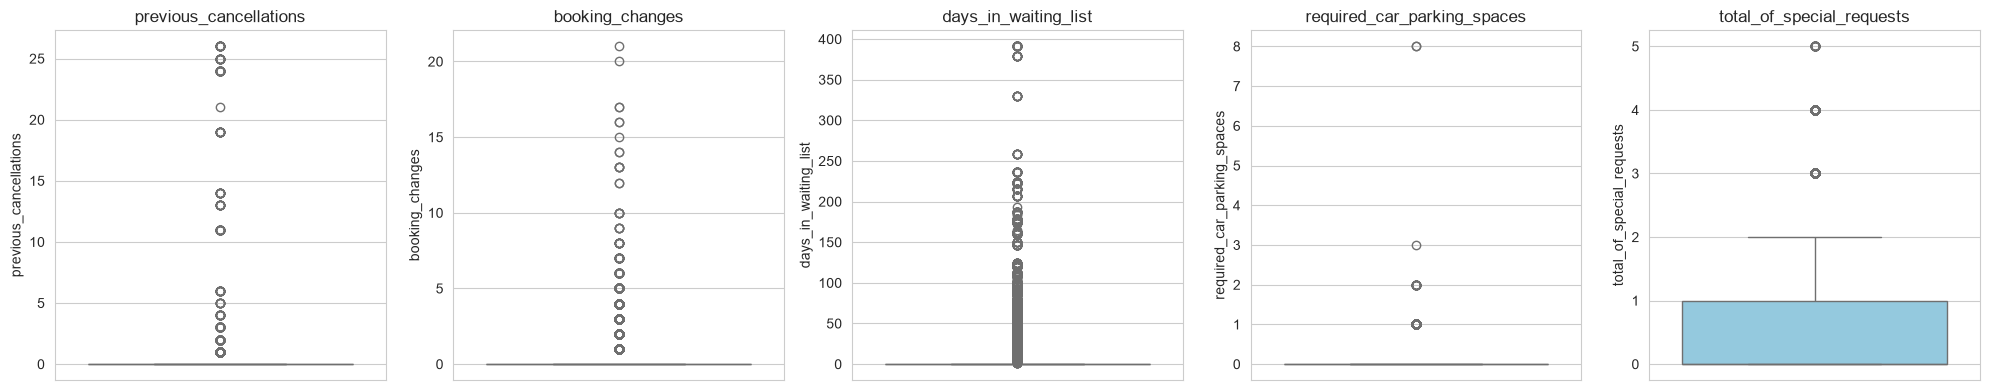

In [23]:
# Daftar kolom numerik
num_cols = ["previous_cancellations", "booking_changes", "days_in_waiting_list",
            "required_car_parking_spaces", "total_of_special_requests"]

# Membuat boxplot untuk setiap kolom numerik
fig, axes = plt.subplots(1, 5, figsize=(20, 4))  # membuat 5 grafik dalam 1 baris
for i, col in enumerate(num_cols):  # perulangan untuk setiap kolom numerik
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")  # membuat boxplot
    axes[i].set_title(col)  # memberi judul grafik
plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik

In [24]:
# Menghitung jumlah outlier dengan metode IQR (Interquartile Range) untuk setiap kolom numerik
outlier_list = []  # list kosong untuk menampung hasil
for col in num_cols:  # perulangan untuk setiap kolom numerik
    q1 = df[col].quantile(0.25)  # kuartil 1
    q3 = df[col].quantile(0.75)  # kuartil 3
    iqr = q3 - q1  # jarak antar kuartil
    batas_bawah = q1 - 1.5 * iqr  # batas bawah outlier
    batas_atas = q3 + 1.5 * iqr  # batas atas outlier
    jumlah = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()  # jumlah data di luar batas
    outlier_list.append([col, batas_bawah, batas_atas, jumlah, round(jumlah / len(df) * 100, 2), df[col].max()])

# Menampilkan hasil dalam bentuk tabel
pd.DataFrame(outlier_list, columns=["Kolom", "Batas Bawah", "Batas Atas", "Jumlah Outlier", "Persentase (%)", "Nilai Maksimum"])

,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%),Nilai Maksimum
0,previous_cancellations,0.0,0.0,4513,5.40,26
1,booking_changes,0.0,0.0,12700,15.20,21
2,days_in_waiting_list,0.0,0.0,2585,3.09,391
3,required_car_parking_spaces,0.0,0.0,5227,6.25,8
4,total_of_special_requests,-1.5,2.5,2051,2.45,5


**Penanganan outlier: outlier dipertahankan.** Alasannya:

- Semua kolom numerik adalah **data hitungan (count)** yang mayoritas bernilai 0, sehingga nilai lebih dari 0 otomatis terdeteksi sebagai "outlier" oleh metode IQR. Nilai-nilai ini **valid secara bisnis**, misalnya tamu yang pernah membatalkan 26 kali (kemungkinan agen perjalanan) atau reservasi grup yang menunggu 391 hari di waiting list.
- Justru nilai-nilai "ekstrem" ini membawa informasi penting tentang perilaku pembatalan.
- Untuk model berbasis jarak/linear, efek outlier dikurangi dengan **RobustScaler** (memakai median dan IQR). Model berbasis pohon (*tree-based*) tidak sensitif terhadap outlier.

# 4. Exploratory Data Analysis (EDA)

**Goal:** melihat hubungan antara variabel independen (fitur) dan variabel dependen (`is_canceled`).

## 4.1 Distribusi Target

,Jumlah,Persentase (%)
is_canceled,,
0,52795,63.17
1,30777,36.83


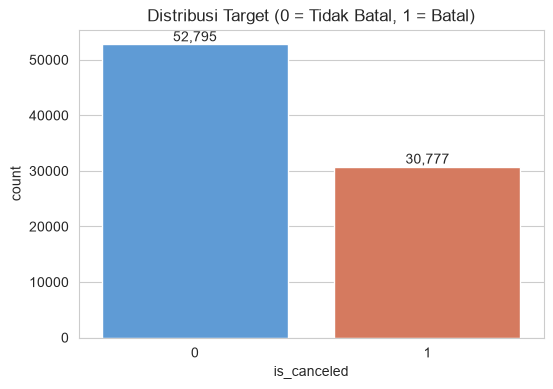

In [25]:
# Menghitung jumlah dan persentase setiap kelas target
target_count = df["is_canceled"].value_counts()  # jumlah data per kelas
target_pct = df["is_canceled"].value_counts(normalize=True) * 100  # persentase data per kelas
display(pd.DataFrame({"Jumlah": target_count, "Persentase (%)": target_pct.round(2)}))

# Membuat grafik distribusi target
plt.figure(figsize=(6, 4))  # ukuran grafik
ax = sns.countplot(x="is_canceled", data=df, palette=["#4C9BE8", "#E8704C"])  # grafik jumlah data per kelas
for p in ax.patches:  # menambahkan label jumlah di atas setiap batang
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi Target (0 = Tidak Batal, 1 = Batal)")  # judul grafik
plt.show()  # menampilkan grafik

**Insight:** sekitar **36,8%** reservasi dibatalkan. Proporsi target **sedikit tidak seimbang (*mildly imbalanced*)** dengan rasio ±63:37. Kondisi ini tidak ekstrem, tetapi tetap perlu diperhatikan: split data dibuat *stratified*, dan pengaruh `class_weight` akan diuji di tahap modeling.

## 4.2 Fitur Kategorikal vs Target

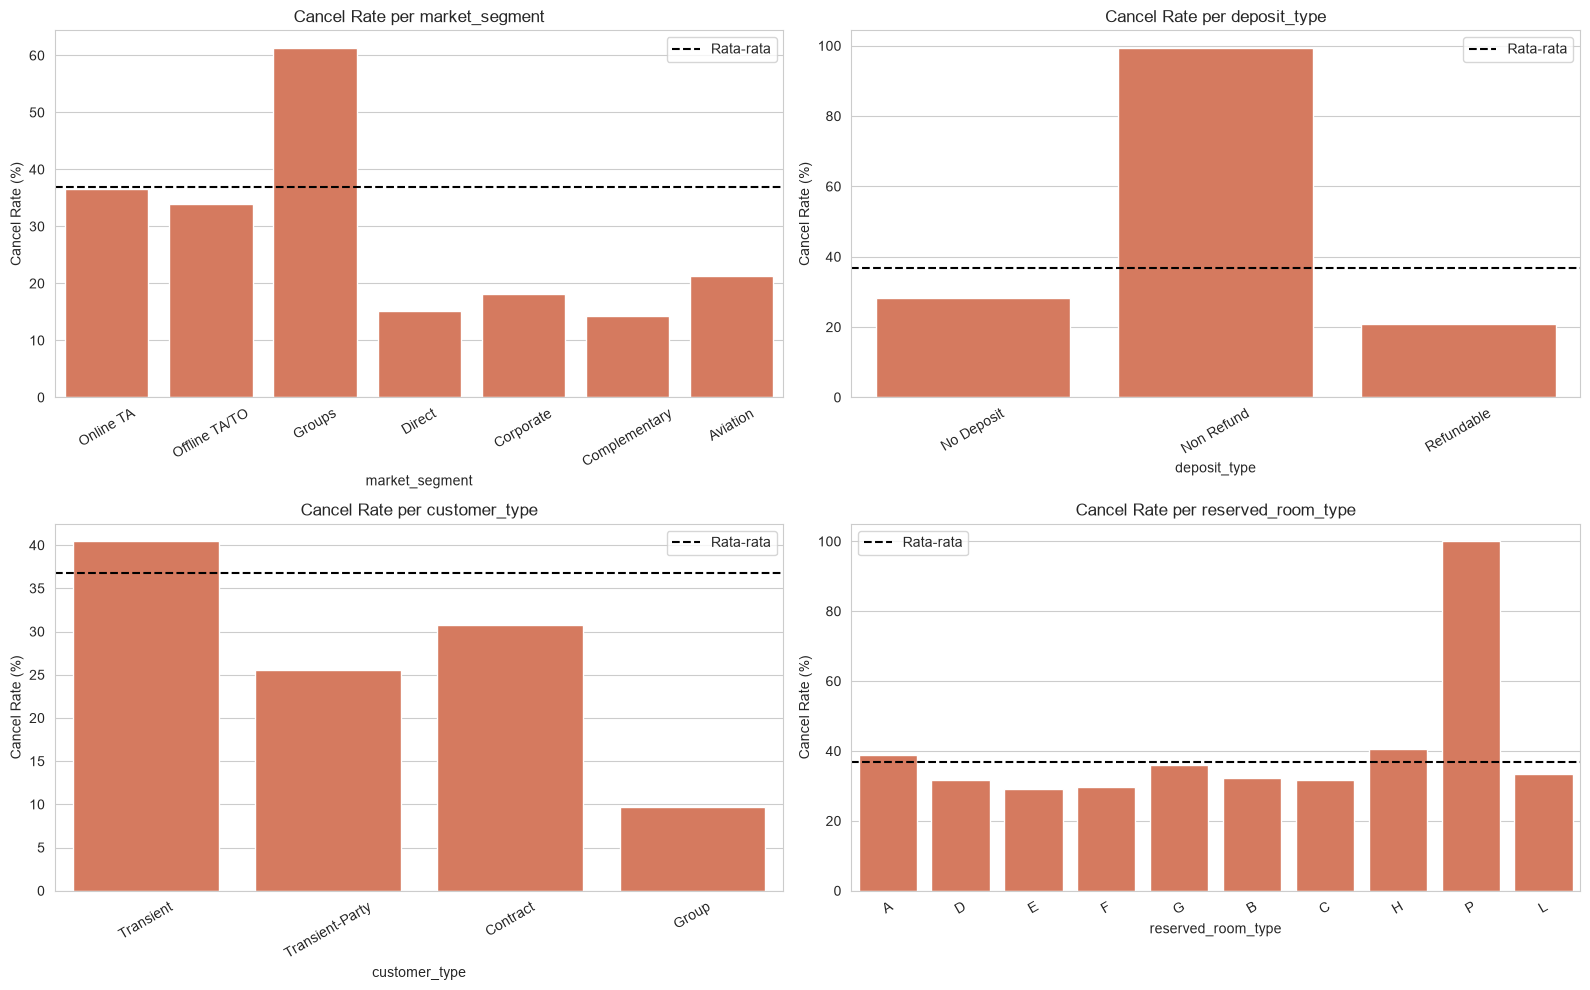

In [26]:
# Fungsi sederhana untuk membuat tabel tingkat pembatalan per kategori
def cancel_rate(col):
    tabel = df.groupby(col)["is_canceled"].agg(["count", "mean"])  # menghitung jumlah data dan rata-rata pembatalan
    tabel.columns = ["Jumlah Booking", "Cancel Rate"]  # mengganti nama kolom
    tabel["Cancel Rate"] = (tabel["Cancel Rate"] * 100).round(2)  # mengubah ke dalam persen
    return tabel.sort_values("Jumlah Booking", ascending=False)  # mengurutkan berdasarkan jumlah booking terbanyak

# Daftar kolom kategorikal yang akan dianalisis
cat_plot_cols = ["market_segment", "deposit_type", "customer_type", "reserved_room_type"]

# Membuat grafik tingkat pembatalan untuk setiap kolom kategorikal
fig, axes = plt.subplots(2, 2, figsize=(16, 10))  # membuat 4 grafik (2 baris x 2 kolom)
axes = axes.flatten()  # mengubah susunan grafik menjadi 1 dimensi agar mudah dipakai di perulangan
for i, col in enumerate(cat_plot_cols):  # perulangan untuk setiap kolom kategorikal
    tabel = cancel_rate(col)  # menghitung tingkat pembatalan
    sns.barplot(x=tabel.index, y=tabel["Cancel Rate"], ax=axes[i], color="#E8704C")  # grafik batang tingkat pembatalan
    axes[i].axhline(df["is_canceled"].mean() * 100, color="black", linestyle="--", label="Rata-rata")  # garis rata-rata
    axes[i].set_title("Cancel Rate per " + col)  # judul grafik
    axes[i].set_ylabel("Cancel Rate (%)")  # label sumbu y
    axes[i].tick_params(axis="x", rotation=30)  # memiringkan label sumbu x
    axes[i].legend()  # menampilkan keterangan garis
plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik

In [27]:
# Menampilkan tabel tingkat pembatalan untuk setiap kolom kategorikal
for col in cat_plot_cols:  # perulangan untuk setiap kolom kategorikal
    display(cancel_rate(col))  # menampilkan tabel

,Jumlah Booking,Cancel Rate
market_segment,,
Online TA,39460,36.58
Offline TA/TO,17025,34.01
Groups,13721,61.31
Direct,8898,15.14
Corporate,3792,18.09
Complementary,511,14.29
Aviation,165,21.21


,Jumlah Booking,Cancel Rate
deposit_type,,
No Deposit,73351,28.23
Non Refund,10111,99.38
Refundable,110,20.91


,Jumlah Booking,Cancel Rate
customer_type,,
Transient,62732,40.44
Transient-Party,17535,25.58
Contract,2882,30.71
Group,423,9.69


,Jumlah Booking,Cancel Rate
reserved_room_type,,
A,60041,38.96
D,13526,31.56
E,4649,29.06
F,2037,29.75
G,1447,35.87
B,786,32.32
C,673,31.65
H,401,40.65
P,9,100.00


**Insight fitur kategorikal:**

1. **`deposit_type`** adalah pembeda paling kuat. Reservasi **Non Refund** dibatalkan **±99%**, jauh di atas *No Deposit* (±28%). Secara intuisi ini terbalik (tamu yang sudah bayar tidak bisa refund seharusnya jarang batal). Dalam penelitian sumber datanya, pola ini dikaitkan dengan reservasi dari agen/grup yang memblok kamar dengan deposit lalu membatalkannya. Bagi hotel, uangnya tetap masuk, tetapi kamarnya kosong.
2. **`market_segment`**: segmen **Groups** (±61%) dan **Online TA** (±37%) paling sering batal. Segmen **Direct** dan **Corporate** (±15–18%) jauh lebih stabil.
3. **`customer_type`**: tipe **Transient** (tamu individu, ±40%) lebih sering batal dibanding **Group** (±10%) dan **Transient-Party**.
4. **`reserved_room_type`**: perbedaannya relatif kecil antar tipe kamar (±29–41%), kecuali kategori yang sangat jarang.

,Jumlah Booking,Cancel Rate
country,,
PRT,34096,56.18
GBR,8495,20.29
FRA,7307,18.69
ESP,5996,25.78
DEU,5116,16.50
ITA,2658,35.18
IRL,2340,24.62
BEL,1648,19.78
BRA,1553,37.60


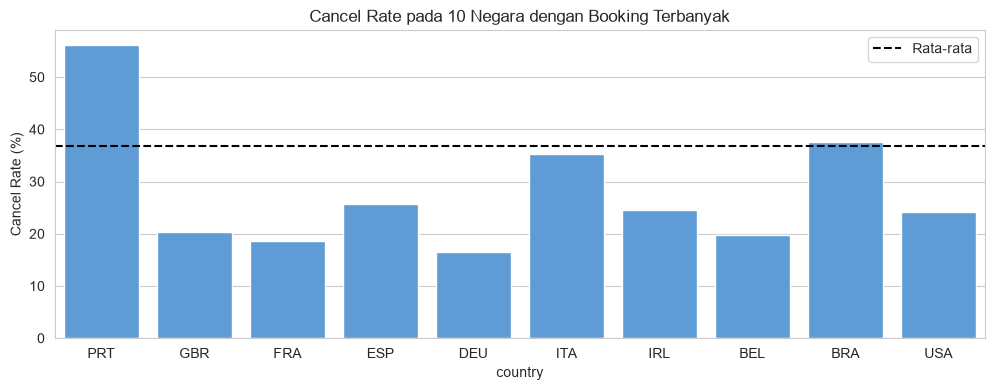

In [28]:
# Menampilkan 10 negara dengan jumlah booking terbanyak beserta tingkat pembatalannya
top_country = cancel_rate("country").head(10)
display(top_country)

# Membuat grafik tingkat pembatalan untuk 10 negara teratas
plt.figure(figsize=(12, 4))  # ukuran grafik
sns.barplot(x=top_country.index, y=top_country["Cancel Rate"], color="#4C9BE8")  # grafik batang
plt.axhline(df["is_canceled"].mean() * 100, color="black", linestyle="--", label="Rata-rata")  # garis rata-rata
plt.title("Cancel Rate pada 10 Negara dengan Booking Terbanyak")  # judul grafik
plt.ylabel("Cancel Rate (%)")  # label sumbu y
plt.legend()  # menampilkan keterangan garis
plt.show()  # menampilkan grafik

In [29]:
# Menghitung persentase booking dari negara-negara yang jumlah bookingnya kurang dari 100
jumlah_per_negara = df["country"].value_counts()  # jumlah booking per negara
negara_jarang = jumlah_per_negara[jumlah_per_negara < 100]  # negara dengan booking kurang dari 100
print("Jumlah negara                         :", df["country"].nunique())
print("Jumlah negara dengan booking < 100    :", len(negara_jarang))
print("Total booking dari negara tersebut    :", negara_jarang.sum(), "(", round(negara_jarang.sum() / len(df) * 100, 2), "% )")

Jumlah negara                         : 162
Jumlah negara dengan booking < 100    : 128
Total booking dari negara tersebut    : 1971 ( 2.36 % )


**Insight `country`:**
- Tamu dari **Portugal (PRT)**, yaitu tamu domestik, memiliki tingkat pembatalan sangat tinggi (**±56%**). Tamu dari negara Eropa lain seperti GBR, FRA, dan DEU hanya **±16–20%**. Tamu domestik lebih mudah memesan lalu membatalkan karena tidak terikat tiket pesawat.
- Kolom `country` memiliki **kardinalitas tinggi** (162 negara), tetapi 128 negara hanya menyumbang ±2% data. Negara-negara langka ini akan digabung menjadi satu kategori saat *encoding*.

## 4.3 Fitur Numerik vs Target

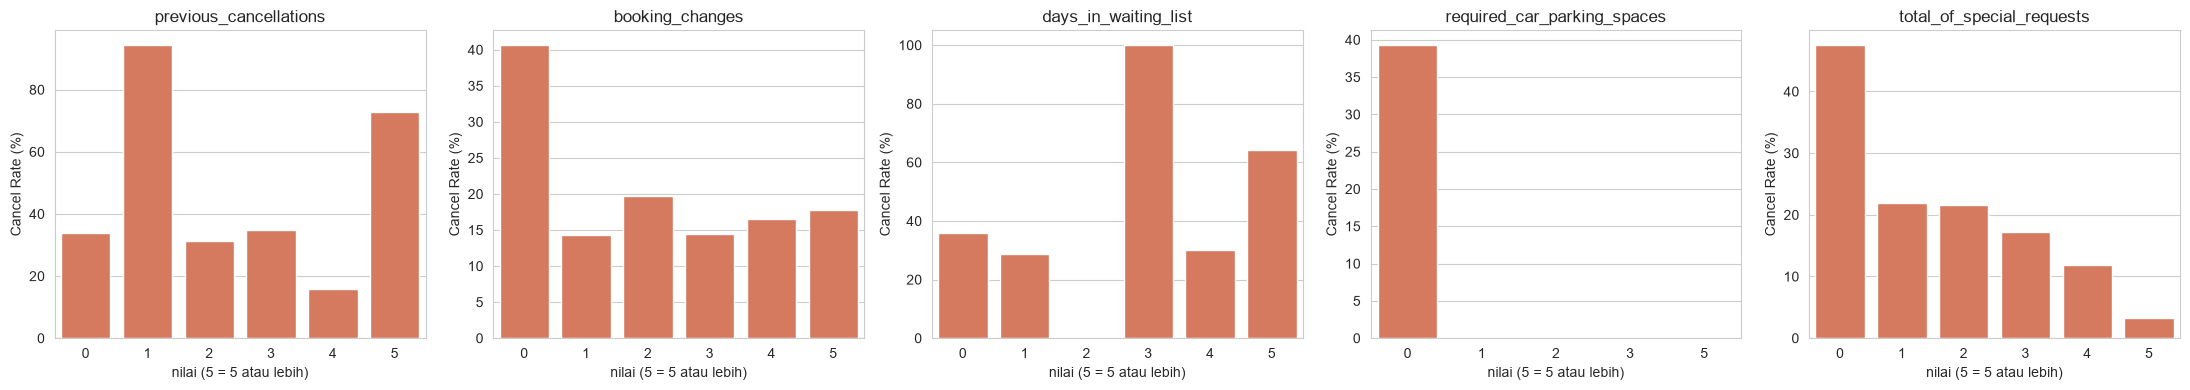

In [30]:
# Membuat grafik tingkat pembatalan berdasarkan nilai fitur numerik
fig, axes = plt.subplots(1, 5, figsize=(22, 4))  # membuat 5 grafik dalam 1 baris
for i, col in enumerate(num_cols):  # perulangan untuk setiap kolom numerik
    nilai = df[col].clip(upper=5)  # nilai di atas 5 digabung menjadi 5 agar grafik mudah dibaca
    rate = df.groupby(nilai)["is_canceled"].mean() * 100  # tingkat pembatalan per nilai
    sns.barplot(x=rate.index, y=rate.values, ax=axes[i], color="#E8704C")  # grafik batang
    axes[i].set_title(col)  # judul grafik
    axes[i].set_xlabel("nilai (5 = 5 atau lebih)")  # label sumbu x
    axes[i].set_ylabel("Cancel Rate (%)")  # label sumbu y
plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik

In [31]:
# Membandingkan rata-rata nilai fitur numerik antara booking batal dan tidak batal
df.groupby("is_canceled")[num_cols].mean().round(3)

,previous_cancellations,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
is_canceled,,,,,
0,0.016,0.293,1.572,0.1,0.716
1,0.208,0.097,3.632,0.0,0.327


**Insight fitur numerik:**

1. **`total_of_special_requests`**: semakin banyak permintaan khusus, semakin kecil kemungkinan batal. Tanpa permintaan khusus, tingkat pembatalan ±48%. Dengan 1 permintaan, turun menjadi ±22%. Permintaan khusus menunjukkan tamu benar-benar berencana datang.
2. **`required_car_parking_spaces`**: reservasi yang meminta parkir **tidak pernah dibatalkan (0%)**. Polanya sangat "sempurna" sehingga patut dicurigai: kemungkinan permintaan parkir baru tercatat saat tamu tiba (check-in). Ini bisa menjadi **potensi data leakage** dan akan diuji di tahap Experiment.
3. **`previous_cancellations`**: tamu yang pernah membatalkan 1 kali memiliki tingkat pembatalan sangat tinggi (±94%).
4. **`booking_changes`**: reservasi yang pernah diubah lebih jarang dibatalkan (±14–20%) dibanding yang tidak pernah diubah (±41%). Menurut deskripsi data, kolom ini dihitung **sampai check-in atau pembatalan**, sehingga juga perlu diwaspadai sebagai potensi leakage.
5. **`days_in_waiting_list`**: reservasi yang sempat masuk waiting list lebih sering batal.

## 4.4 Korelasi Antar Fitur Numerik (Multikolinearitas)

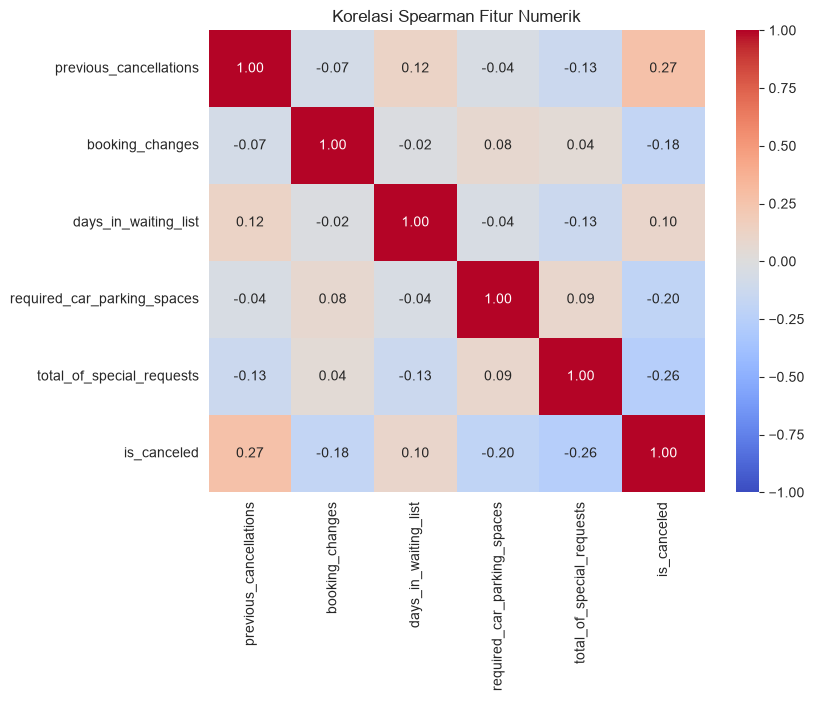

In [32]:
# Menghitung korelasi Spearman antar fitur numerik dan target (Spearman cocok untuk data count yang tidak normal)
korelasi = df[num_cols + ["is_canceled"]].corr(method="spearman")

# Menampilkan korelasi dalam bentuk heatmap
plt.figure(figsize=(8, 6))  # ukuran grafik
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)  # heatmap korelasi
plt.title("Korelasi Spearman Fitur Numerik")  # judul grafik
plt.show()  # menampilkan grafik

**Insight:** korelasi antar fitur numerik sangat lemah (semua |r| ≤ 0,13), sehingga **tidak ada masalah multikolinearitas** dan semua fitur numerik bisa dipakai. Korelasi dengan target juga tergolong lemah: `previous_cancellations` (+0,27), `total_of_special_requests` (−0,26), `required_car_parking_spaces` (−0,20), dan `booking_changes` (−0,18). Tidak ada satu fitur numerik pun yang bisa memprediksi pembatalan sendirian, sehingga diperlukan model yang bisa menggabungkan banyak fitur sekaligus.

## 4.5 Validasi Pola dengan Dataset Pendukung

Apakah pola pembatalan yang kita temukan hanya terjadi di hotel ini, atau juga terjadi di hotel lain? Kita membandingkan dataset utama dengan **Hotel Reservations** (hotel lain) pada kolom-kolom yang setara.

Permintaan khusus


,Dataset Utama,Hotel Reservations
nilai,,
0,47.5,43.2
1,22.0,23.8
2,21.6,14.6
3,16.4,0.0


Meminta parkir (0/1)


,Dataset Utama,Hotel Reservations
nilai,,
0,39.3,33.5
1,0.0,10.1


Pernah membatalkan (0/1)


,Dataset Utama,Hotel Reservations
nilai,,
0,33.7,33.0
1,91.5,4.7


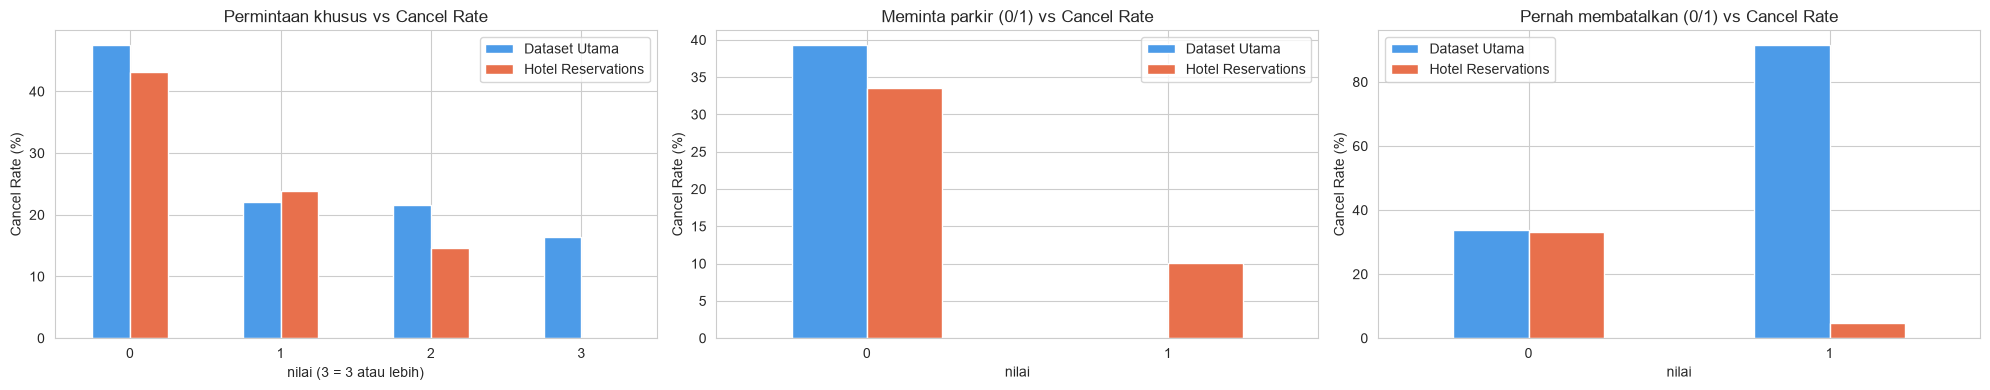

In [33]:
# Fungsi sederhana untuk menghitung tingkat pembatalan (%) per nilai sebuah kolom
def rate_per_nilai(data, kolom, target="is_canceled"):
    return (data.groupby(kolom)[target].mean() * 100).round(1)  # rata-rata target per nilai, dalam persen

# Menyamakan skala nilai: permintaan khusus 3 atau lebih digabung menjadi 3, parkir dan pembatalan sebelumnya dibuat 0/1
validasi = {
    "Permintaan khusus": (df["total_of_special_requests"].clip(upper=3), df_hr["no_of_special_requests"].clip(upper=3)),
    "Meminta parkir (0/1)": (df["required_car_parking_spaces"].clip(upper=1), df_hr["required_car_parking_space"].clip(upper=1)),
    "Pernah membatalkan (0/1)": (df["previous_cancellations"].clip(upper=1), df_hr["no_of_previous_cancellations"].clip(upper=1))
}

# Membuat grafik perbandingan untuk setiap pola
fig, axes = plt.subplots(1, 3, figsize=(20, 4))  # membuat 3 grafik berdampingan
for i, (judul, (kolom_utama, kolom_hr)) in enumerate(validasi.items()):  # perulangan untuk setiap pola
    tabel = pd.DataFrame({
        "Dataset Utama": rate_per_nilai(df.assign(nilai=kolom_utama), "nilai"),  # tingkat pembatalan di dataset utama
        "Hotel Reservations": rate_per_nilai(df_hr.assign(nilai=kolom_hr), "nilai")  # tingkat pembatalan di hotel lain
    })
    tabel.plot(kind="bar", ax=axes[i], color=["#4C9BE8", "#E8704C"], rot=0)  # grafik batang berdampingan
    axes[i].set_title(judul + " vs Cancel Rate")  # judul grafik
    axes[i].set_xlabel("nilai (3 = 3 atau lebih)" if i == 0 else "nilai")  # label sumbu x
    axes[i].set_ylabel("Cancel Rate (%)")  # label sumbu y
    print(judul)  # menampilkan nama pola
    display(tabel)  # menampilkan tabel angka
plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik

In [34]:
# Jumlah tamu yang pernah membatalkan di dataset Hotel Reservations
print("Jumlah reservasi dengan pembatalan sebelumnya di Hotel Reservations:", (df_hr["no_of_previous_cancellations"] > 0).sum())

# Tingkat pembatalan per segmen pasar di Hotel Reservations
cancel_rate_hr = df_hr.groupby("market_segment_type")["is_canceled"].agg(["count", "mean"])  # jumlah dan rata-rata pembatalan
cancel_rate_hr.columns = ["Jumlah Booking", "Cancel Rate"]  # mengganti nama kolom
cancel_rate_hr["Cancel Rate"] = (cancel_rate_hr["Cancel Rate"] * 100).round(1)  # mengubah ke persen
cancel_rate_hr.sort_values("Jumlah Booking", ascending=False)

Jumlah reservasi dengan pembatalan sebelumnya di Hotel Reservations: 338


,Jumlah Booking,Cancel Rate
market_segment_type,,
Online,23214,36.5
Offline,10528,29.9
Corporate,2017,10.9
Complementary,391,0.0
Aviation,125,29.6


**Insight validasi dengan hotel lain:**

| Pola | Dataset Utama | Hotel Reservations | Kesimpulan |
|---|---|---|---|
| Semakin banyak permintaan khusus, semakin jarang batal | 48% → 22% → 16% | 43% → 24% → 0% | ✅ **Konsisten** |
| Tamu yang meminta parkir jarang batal | 39% → 0% | 34% → 10% | ✅ **Konsisten**, tetapi di hotel lain tidak sampai 0%. Ini makin menguatkan dugaan bahwa angka 0% di hotel kita dipengaruhi waktu pencatatan data |
| Online lebih sering batal dibanding Corporate/Complementary | Online TA 37%, Corporate 18% | Online 37%, Corporate 11% | ✅ **Konsisten** |
| Tamu yang pernah membatalkan cenderung batal lagi | 34% → **92%** | 33% → **5%** | ❌ **Tidak konsisten**. Di hotel lain hanya 338 reservasi yang punya riwayat batal, dan kebanyakan tamu langganan yang akhirnya datang. Pola ini **khusus** untuk hotel kita, kemungkinan dari agen/grup yang berulang kali memblok lalu membatalkan kamar |

Artinya, faktor **komitmen tamu** (permintaan khusus, parkir) dan **saluran pemesanan** adalah pola umum di industri hotel, sehingga insight dari model ini cukup bisa digeneralisasi. Sebaliknya, pola **riwayat pembatalan** perlu hati-hati jika model dipakai di hotel lain.

### Faktor yang tidak tersedia di dataset utama: *Lead Time*

Kedua dataset pendukung memiliki kolom `lead_time` (jarak hari antara reservasi dibuat dan tanggal kedatangan), yang **tidak ada di dataset utama**. Kita melihat seberapa kuat pengaruhnya.

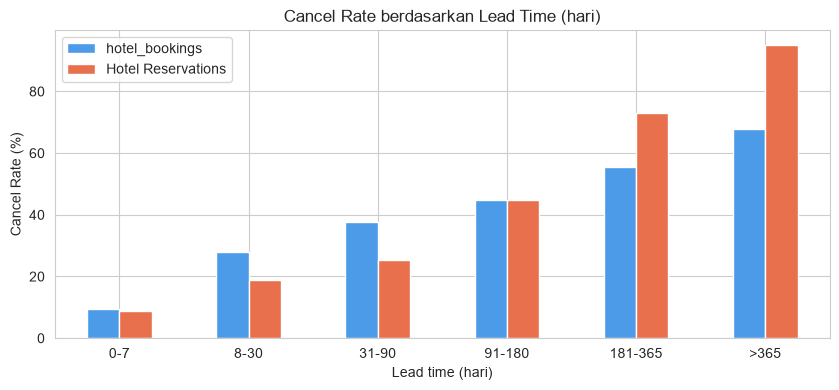

,hotel_bookings,Hotel Reservations
lead_time,,
0-7,9.6,8.9
8-30,27.9,18.9
31-90,37.7,25.3
91-180,44.7,44.9
181-365,55.5,72.9
>365,67.7,95.1


In [35]:
# Membagi lead_time menjadi beberapa kelompok
batas = [-1, 7, 30, 90, 180, 365, 1000]  # batas kelompok lead time (hari)
label = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]  # nama kelompok lead time

lead_hb = df_hb.groupby(pd.cut(df_hb["lead_time"], bins=batas, labels=label), observed=True)["is_canceled"].mean() * 100  # cancel rate di hotel_bookings
lead_hr = df_hr.groupby(pd.cut(df_hr["lead_time"], bins=batas, labels=label), observed=True)["is_canceled"].mean() * 100  # cancel rate di Hotel Reservations
tabel_lead = pd.DataFrame({"hotel_bookings": lead_hb.round(1), "Hotel Reservations": lead_hr.round(1)})

# Membuat grafik cancel rate berdasarkan lead time
tabel_lead.plot(kind="bar", figsize=(10, 4), color=["#4C9BE8", "#E8704C"], rot=0)  # grafik batang berdampingan
plt.title("Cancel Rate berdasarkan Lead Time (hari)")  # judul grafik
plt.xlabel("Lead time (hari)")  # label sumbu x
plt.ylabel("Cancel Rate (%)")  # label sumbu y
plt.show()  # menampilkan grafik
tabel_lead

**Insight:** di kedua dataset pendukung, **semakin jauh jarak pemesanan dengan tanggal kedatangan, semakin besar peluang batal**. Reservasi yang dibuat ≤ 7 hari sebelum kedatangan hanya batal ±9–10%, sedangkan reservasi yang dibuat lebih dari setahun sebelumnya batal ±68–95%. *Lead time* adalah faktor yang sangat kuat, tetapi **tidak tersedia di dataset utama**. Ini menjadi **limitasi utama** model kita, dan dampaknya diukur di bagian 8.3.

# 5. Data Preparation

Bagian ini menjawab pertanyaan panduan pada Roadmap:

| Pertanyaan | Jawaban |
|---|---|
| Bagaimana menangani missing value dan duplikat? | `country` kosong diisi `"Unknown"` di dalam pipeline. Duplikat dipertahankan (lihat 3.2) |
| Bagaimana mengonversi dan memverifikasi tipe data? | Tipe data sudah sesuai, tidak perlu konversi |
| Apakah ada kolinearitas? | Tidak ada korelasi tinggi antar fitur numerik |
| Apakah perbedaan skala penting? | Penting untuk model berbasis jarak/linear (KNN, Logistic Regression), sehingga dipakai **RobustScaler**. Model pohon tidak terpengaruh |
| Bagaimana dengan kardinalitas? | `country` (162 kategori) diringkas menjadi `sub_region` (±17 kategori) dengan dataset pendukung `continents2.csv`. Untuk semua kolom kategorikal, One-Hot Encoding memakai `min_frequency=100`, sehingga kategori dengan data < 100 digabung menjadi satu kategori "infrequent" |
| Bagaimana menangani outlier? | Dipertahankan (nilai valid secara bisnis). RobustScaler mengurangi pengaruhnya |
| Bagaimana mengubah data kategorikal menjadi numerik? | **One-Hot Encoding** untuk semua kolom kategorikal karena semuanya **nominal** (tidak memiliki urutan) |
| Fitur apa yang dipakai? | Fitur final ditentukan lewat eksperimen di tahap Modeling: uji potensi leakage (`booking_changes`, `required_car_parking_spaces`) dan uji fitur negara (`country` vs `region` vs `sub_region`) |

**Feature Engineering:** dataset hanya memiliki 10 kolom tanpa informasi waktu dan harga, sehingga ruang untuk membuat fitur baru terbatas. Kita membuat 3 fitur baru yang bermakna bisnis:
- `is_domestic`: 1 jika tamu berasal dari Portugal (PRT), 0 jika tidak. Fitur ini dibuat karena EDA menunjukkan tamu domestik memiliki perilaku pembatalan yang sangat berbeda.
- `region`: benua asal tamu (Europe, Asia, Americas, Africa, Oceania), hasil pemetaan `country` dengan dataset pendukung `continents2.csv`.
- `sub_region`: wilayah yang lebih rinci (misalnya Southern Europe, Western Europe, Northern Europe), juga dari `continents2.csv`.

Fitur `region` dan `sub_region` dibuat untuk **mengurangi kardinalitas** `country` (162 kategori) menjadi kelompok yang lebih sedikit, lebih stabil, dan lebih mudah dijelaskan ke stakeholder. Kedua fitur ini juga bisa menangani negara baru yang belum pernah muncul di data training. Fitur mana yang paling baik dipakai (`country`, `region`, atau `sub_region`) akan diuji di tahap Modeling.

In [36]:
# Feature engineering 1: membuat fitur is_domestic (1 = tamu dari Portugal, 0 = tamu luar negeri / tidak diketahui)
df["is_domestic"] = (df["country"] == "PRT").astype(int)

# Mengecek tingkat pembatalan berdasarkan fitur baru
df.groupby("is_domestic")["is_canceled"].agg(["count", "mean"])

,count,mean
is_domestic,,
0,49476,0.234882
1,34096,0.561825


In [37]:
# Feature engineering 2: membuat kamus (dictionary) kode negara -> benua dan kode negara -> sub-region dari continents2
peta_region = dict(zip(df_country["alpha-3"], df_country["region"]))  # contoh: "PRT" -> "Europe"
peta_sub_region = dict(zip(df_country["alpha-3"], df_country["sub-region"]))  # contoh: "PRT" -> "Southern Europe"

# Menambahkan kode negara yang tidak sesuai standar ISO secara manual
peta_region["CN"] = "Asia"  # CN = China
peta_sub_region["CN"] = "Eastern Asia"
peta_region["TMP"] = "Asia"  # TMP = kode lama Timor-Leste
peta_sub_region["TMP"] = "South-eastern Asia"

# Membuat kolom region dan sub_region, negara yang kosong diisi "Unknown"
df["region"] = df["country"].map(peta_region).fillna("Unknown")
df["sub_region"] = df["country"].map(peta_sub_region).fillna("Unknown")

print("Jumlah kategori country    :", df["country"].nunique())
print("Jumlah kategori region     :", df["region"].nunique())
print("Jumlah kategori sub_region :", df["sub_region"].nunique())

Jumlah kategori country    : 162
Jumlah kategori region     : 6
Jumlah kategori sub_region : 17


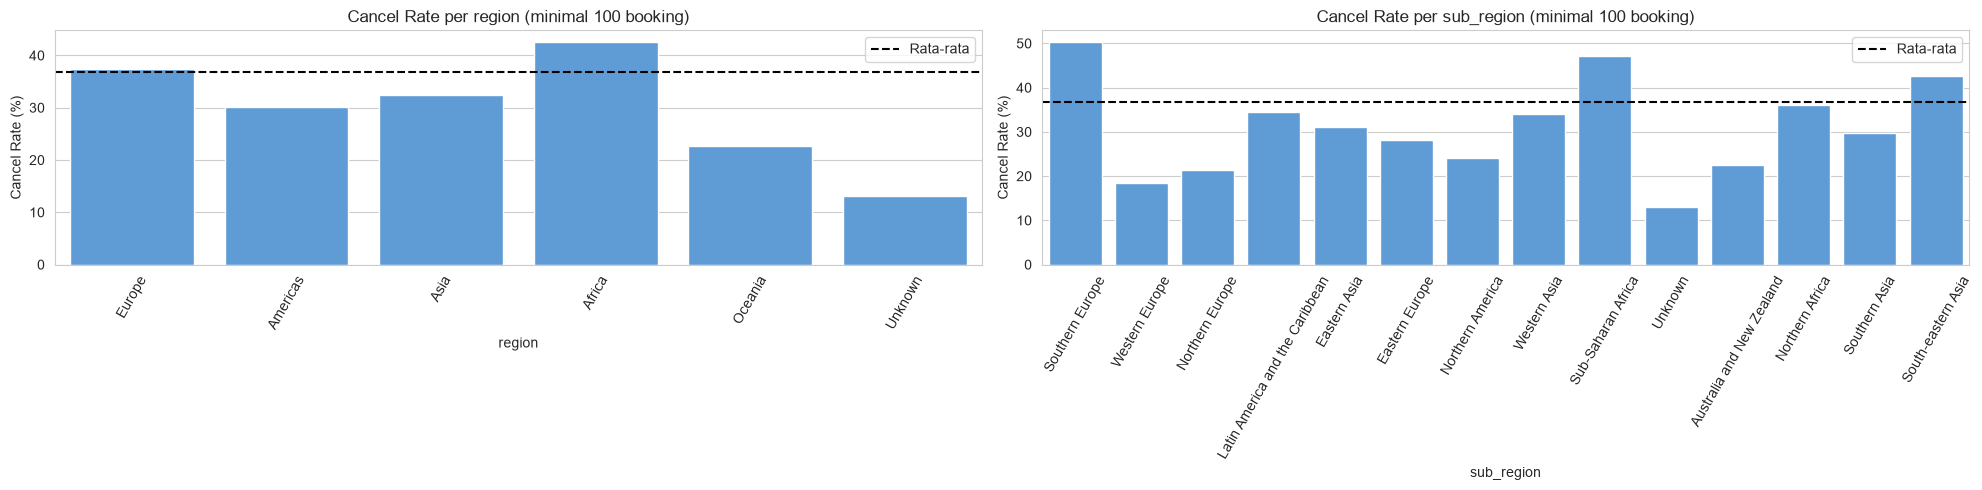

,Jumlah Booking,Cancel Rate
sub_region,,
Southern Europe,43093,50.40
Western Europe,17761,18.52
Northern Europe,12820,21.44
Latin America and the Caribbean,2012,34.39
Eastern Asia,1894,30.99
Eastern Europe,1824,28.12
Northern America,1472,24.12
Western Asia,855,34.04
Sub-Saharan Africa,449,47.22


In [38]:
# Melihat tingkat pembatalan per region dan sub_region
fig, axes = plt.subplots(1, 2, figsize=(20, 5))  # membuat 2 grafik berdampingan
for i, col in enumerate(["region", "sub_region"]):  # perulangan untuk region dan sub_region
    tabel = cancel_rate(col)  # menghitung jumlah booking dan cancel rate
    tabel = tabel[tabel["Jumlah Booking"] >= 100]  # hanya menampilkan kelompok dengan minimal 100 booking
    sns.barplot(x=tabel.index, y=tabel["Cancel Rate"], ax=axes[i], color="#4C9BE8")  # grafik batang
    axes[i].axhline(df["is_canceled"].mean() * 100, color="black", linestyle="--", label="Rata-rata")  # garis rata-rata
    axes[i].set_title("Cancel Rate per " + col + " (minimal 100 booking)")  # judul grafik
    axes[i].set_ylabel("Cancel Rate (%)")  # label sumbu y
    axes[i].tick_params(axis="x", rotation=60)  # memiringkan label sumbu x
    axes[i].legend()  # menampilkan keterangan
plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik
cancel_rate("sub_region").head(10)

**Insight:**
- Pada level **benua (`region`)**, ±90% tamu berasal dari Eropa, sehingga fitur ini **terlalu kasar** untuk membedakan perilaku tamu.
- Pada level **`sub_region`**, perbedaannya jelas: **Southern Europe** (termasuk Portugal dan Spanyol) memiliki cancel rate ±50%, sedangkan **Western Europe** (Prancis, Jerman) dan **Northern Europe** (Inggris, Irlandia) hanya ±19–21%.

## 5.1 Define Feature & Target, lalu Split Data

Data dibagi menjadi **80% train** dan **20% test** dengan `stratify=y`, agar proporsi pembatalan sama di kedua bagian. Data test **tidak disentuh** sampai tahap evaluasi akhir, supaya hasil evaluasi tidak bias.

In [39]:
# Memisahkan fitur (X) dan target (y)
X = df.drop(columns="is_canceled")  # semua kolom kecuali target menjadi fitur
y = df["is_canceled"]  # kolom target

# Membagi data menjadi data train (80%) dan data test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,  # 20% data untuk test
    stratify=y,  # menjaga proporsi target tetap sama di train dan test
    random_state=42  # agar hasil pembagian selalu sama setiap dijalankan
)

print("Ukuran data train :", X_train.shape)
print("Ukuran data test  :", X_test.shape)
print("Proporsi batal di train :", round(y_train.mean() * 100, 2), "%")
print("Proporsi batal di test  :", round(y_test.mean() * 100, 2), "%")

Ukuran data train : (66857, 13)
Ukuran data test  : (16715, 13)
Proporsi batal di train : 36.83 %
Proporsi batal di test  : 36.83 %


## 5.2 Preprocessing Pipeline

Semua langkah preprocessing dimasukkan ke dalam `ColumnTransformer` + `Pipeline`, sehingga:
- preprocessing hanya "belajar" dari data train di setiap fold, sehingga **tidak terjadi data leakage**
- langkah yang sama otomatis diterapkan ke data test dan data baru saat model dipakai

In [40]:
# Daftar kolom kategorikal dan numerik
cat_cols = ["country", "market_segment", "deposit_type", "customer_type", "reserved_room_type"]
num_cols = ["previous_cancellations", "booking_changes", "days_in_waiting_list",
            "required_car_parking_spaces", "total_of_special_requests", "is_domestic"]

# Pipeline untuk kolom kategorikal
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),  # mengisi missing value dengan "Unknown"
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",  # kategori baru yang belum pernah dilihat dimasukkan ke "infrequent"
                             min_frequency=100,  # kategori dengan data < 100 digabung menjadi satu kategori "infrequent"
                             sparse_output=False))  # hasil encoding berupa array biasa (bukan sparse)
])

# Menggabungkan preprocessing kolom kategorikal dan numerik
preprocessor = ColumnTransformer([
    ("cat", cat_pipeline, cat_cols),  # menerapkan cat_pipeline pada kolom kategorikal
    ("num", RobustScaler(), num_cols)  # menerapkan RobustScaler pada kolom numerik
])

# Mencoba preprocessing pada data train untuk melihat hasilnya
X_train_prep = preprocessor.fit_transform(X_train)  # belajar dan mengubah data train
print("Jumlah fitur sebelum preprocessing :", X_train.shape[1])
print("Jumlah fitur setelah preprocessing :", X_train_prep.shape[1])

Jumlah fitur sebelum preprocessing : 13
Jumlah fitur setelah preprocessing : 62


In [41]:
# Menampilkan contoh hasil preprocessing dalam bentuk DataFrame
pd.DataFrame(X_train_prep, columns=preprocessor.get_feature_names_out()).head()

,cat__country_AGO,cat__country_ARG,cat__country_AUS,cat__country_AUT,cat__country_BEL,cat__country_BRA,cat__country_CHE,cat__country_CHN,cat__country_CN,cat__country_DEU,cat__country_DNK,cat__country_ESP,cat__country_FIN,cat__country_FRA,cat__country_GBR,cat__country_HUN,cat__country_IRL,cat__country_ISR,cat__country_ITA,cat__country_JPN,cat__country_LUX,cat__country_MAR,cat__country_NLD,cat__country_NOR,cat__country_POL,cat__country_PRT,cat__country_ROU,cat__country_RUS,cat__country_SWE,cat__country_TUR,cat__country_USA,cat__country_Unknown,cat__country_infrequent_sklearn,cat__market_segment_Aviation,cat__market_segment_Complementary,cat__market_segment_Corporate,cat__market_segment_Direct,cat__market_segment_Groups,cat__market_segment_Offline TA/TO,cat__market_segment_Online TA,cat__deposit_type_No Deposit,cat__deposit_type_Non Refund,cat__deposit_type_infrequent_sklearn,cat__customer_type_Contract,cat__customer_type_Group,cat__customer_type_Transient,cat__customer_type_Transient-Party,cat__reserved_room_type_A,cat__reserved_room_type_B,cat__reserved_room_type_C,cat__reserved_room_type_D,cat__reserved_room_type_E,cat__reserved_room_type_F,cat__reserved_room_type_G,cat__reserved_room_type_H,cat__reserved_room_type_infrequent_sklearn,num__previous_cancellations,num__booking_changes,num__days_in_waiting_list,num__required_car_parking_spaces,num__total_of_special_requests,num__is_domestic
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 6. Experiment Planning

**Goal:** eksperimen dilakukan secara terstruktur sehingga setiap keputusan bisa dipertanggungjawabkan.

| Tahap | Eksperimen | Cara | Output |
|---|---|---|---|
| 1 | **Benchmarking model** | Membandingkan 7 algoritma dengan **5-fold Stratified Cross Validation** pada data train, metrik **F2-score** | Model terbaik |
| 2 | **Penanganan imbalance** | Membandingkan model terbaik dengan dan tanpa `class_weight="balanced"` | Konfigurasi imbalance terbaik |
| 3 | **Uji potensi data leakage** | Membandingkan model dengan dan tanpa fitur `required_car_parking_spaces` dan `booking_changes` | Keputusan fitur final |
| 4 | **Uji fitur negara** | Membandingkan `country` vs `region` vs `sub_region` (hasil feature engineering dengan dataset `continents2.csv`) | Fitur negara final |
| 5 | **Hyperparameter tuning** | `RandomizedSearchCV` pada model terbaik | Parameter terbaik |
| 6 | **Threshold tuning** | Mencari threshold probabilitas dengan **total biaya terendah** (memakai prediksi cross validation pada data train) | Threshold final |
| 7 | **Evaluasi akhir** | Evaluasi model final pada data test, dibandingkan dengan model sebelum tuning dan baseline tanpa model | Hasil akhir |
| 8 | **Uji dampak fitur tambahan** | Melatih model yang sama pada dataset pendukung `hotel_bookings.csv`, dengan dan tanpa fitur yang tidak tersedia di dataset utama (*lead time*, harga, dll) | Besarnya limitasi data |

**Model yang dibandingkan:**
- **Logistic Regression**: model linear sederhana, dipakai sebagai baseline
- **K-Nearest Neighbors**: model berbasis jarak
- **Decision Tree**: model pohon tunggal yang mudah diinterpretasi
- **Random Forest**: ensemble *bagging* dari banyak decision tree
- **AdaBoost**: ensemble *boosting* yang fokus pada data yang salah diprediksi
- **Gradient Boosting**: ensemble *boosting* yang memperbaiki error model sebelumnya secara bertahap
- **HistGradientBoosting**: versi Gradient Boosting yang jauh lebih cepat untuk data besar (cara kerjanya mirip LightGBM)

`random_state=42` dipakai di semua model agar hasil bisa direproduksi.

# 7. Modeling

## 7.1 Benchmarking Model

In [42]:
# Membuat scorer F2-score (beta=2 artinya recall dianggap 2 kali lebih penting dari precision)
f2_scorer = make_scorer(fbeta_score, beta=2)

# Membuat skema 5-fold stratified cross validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Daftar model yang akan dibandingkan (class_weight="balanced" dipakai jika modelnya mendukung)
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
}

In [43]:
# Melakukan cross validation untuk setiap model dan menyimpan hasilnya
hasil_benchmark = []  # list kosong untuk menampung hasil
for nama, model in models.items():  # perulangan untuk setiap model
    pipe = Pipeline([("prep", preprocessor), ("model", model)])  # menggabungkan preprocessing dan model
    skor = cross_val_score(pipe, X_train, y_train, cv=skf, scoring=f2_scorer, n_jobs=-1)  # menghitung F2-score di setiap fold
    hasil_benchmark.append([nama, skor.mean(), skor.std()])  # menyimpan rata-rata dan standar deviasi skor
    print(nama, "selesai")  # penanda proses selesai

# Mengubah hasil menjadi DataFrame dan mengurutkan dari skor tertinggi
df_benchmark = pd.DataFrame(hasil_benchmark, columns=["Model", "Mean F2", "Std F2"])
df_benchmark = df_benchmark.sort_values("Mean F2", ascending=False).reset_index(drop=True)
df_benchmark

Logistic Regression selesai
KNN selesai
Decision Tree selesai
Random Forest selesai
AdaBoost selesai
Gradient Boosting selesai
HistGradientBoosting selesai


,Model,Mean F2,Std F2
0,Random Forest,0.776645,0.005384
1,HistGradientBoosting,0.774972,0.005395
2,Decision Tree,0.768708,0.004768
3,Logistic Regression,0.739461,0.004019
4,Gradient Boosting,0.665004,0.009622
5,KNN,0.661436,0.021919
6,AdaBoost,0.508243,0.015116


**Insight benchmarking:**
- **Random Forest** memiliki rata-rata F2-score tertinggi dan standar deviasi kecil (stabil antar fold), disusul tipis oleh HistGradientBoosting dan Decision Tree.
- Gradient Boosting, KNN, dan AdaBoost memiliki skor F2 rendah karena ketiganya **tidak memakai `class_weight`**. Dengan threshold default 0,5, model-model ini cenderung memprediksi kelas mayoritas (tidak batal), sehingga recall-nya rendah.
- **Random Forest dipilih** sebagai model untuk dikembangkan lebih lanjut.

**Cara kerja Random Forest:** Random Forest membangun **banyak decision tree** (misalnya 100 pohon). Setiap pohon dilatih dengan **sampel data acak** (*bootstrap*) dan pada setiap percabangan hanya mempertimbangkan **sebagian fitur secara acak**. Untuk memprediksi, setiap pohon memberikan "suara" (*voting*), dan probabilitas akhir adalah rata-rata suara semua pohon. Karena setiap pohon berbeda, kesalahan satu pohon akan diimbangi pohon lain, sehingga Random Forest lebih stabil dan tidak mudah *overfitting* dibanding satu decision tree.

## 7.2 Penanganan Imbalance

Kita membandingkan Random Forest **tanpa** dan **dengan** `class_weight="balanced"`. `class_weight="balanced"` memberi bobot lebih besar pada kelas minoritas (batal), sehingga model lebih memperhatikan kelas tersebut. Karena data cukup besar dan imbalance tidak ekstrem (±37%), cara ini dipilih dibanding *oversampling/undersampling*, yang dapat menambah data sintetis atau membuang data asli.

In [44]:
# Membandingkan Random Forest tanpa dan dengan class_weight="balanced"
hasil_imbalance = []  # list kosong untuk menampung hasil
for cw in [None, "balanced"]:  # perulangan untuk dua pilihan class_weight
    rf = RandomForestClassifier(class_weight=cw, n_estimators=100, random_state=42, n_jobs=-1)  # membuat model
    pipe = Pipeline([("prep", preprocessor), ("model", rf)])  # menggabungkan preprocessing dan model
    skor = cross_val_score(pipe, X_train, y_train, cv=skf, scoring=f2_scorer, n_jobs=-1)  # cross validation F2-score
    hasil_imbalance.append([str(cw), skor.mean(), skor.std()])  # menyimpan hasil

pd.DataFrame(hasil_imbalance, columns=["class_weight", "Mean F2", "Std F2"])

,class_weight,Mean F2,Std F2
0,None,0.714324,0.008478
1,balanced,0.776645,0.005384


**Insight:** `class_weight="balanced"` menaikkan F2 dari ±0,714 menjadi ±0,777. Tanpa pembobotan, model cenderung memprediksi kelas mayoritas (tidak batal), sehingga banyak pembatalan terlewat (recall rendah).

## 7.3 Uji Potensi Data Leakage

Di EDA kita menemukan dua fitur yang perlu diwaspadai:
- `required_car_parking_spaces`: semua reservasi yang meminta parkir tidak pernah batal (polanya terlalu "sempurna").
- `booking_changes`: menurut deskripsi data, dihitung sampai check-in atau pembatalan.

Kita mengukur seberapa besar ketergantungan model pada kedua fitur ini.

In [45]:
# Daftar skenario fitur yang akan diuji
skenario = {
    "Semua fitur": [],
    "Tanpa required_car_parking_spaces": ["required_car_parking_spaces"],
    "Tanpa booking_changes": ["booking_changes"],
    "Tanpa keduanya": ["required_car_parking_spaces", "booking_changes"]
}

hasil_leakage = []  # list kosong untuk menampung hasil
for nama, kolom_dibuang in skenario.items():  # perulangan untuk setiap skenario
    num_cols_skenario = [c for c in num_cols if c not in kolom_dibuang]  # kolom numerik yang dipakai
    prep_skenario = ColumnTransformer([
        ("cat", cat_pipeline, cat_cols),  # preprocessing kolom kategorikal
        ("num", RobustScaler(), num_cols_skenario)  # preprocessing kolom numerik tanpa kolom yang dibuang
    ])
    pipe = Pipeline([
        ("prep", prep_skenario),
        ("model", RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1))
    ])
    skor = cross_val_score(pipe, X_train, y_train, cv=skf, scoring=f2_scorer, n_jobs=-1)  # cross validation F2-score
    hasil_leakage.append([nama, skor.mean()])  # menyimpan hasil

pd.DataFrame(hasil_leakage, columns=["Skenario", "Mean F2"])

,Skenario,Mean F2
0,Semua fitur,0.776645
1,Tanpa required_car_parking_spaces,0.762130
2,Tanpa booking_changes,0.776929
3,Tanpa keduanya,0.746020


**Insight uji leakage dan keputusan fitur:**

| Fitur | Dampak jika dibuang | Keputusan |
|---|---|---|
| `booking_changes` | F2 **tidak berubah** | **Dibuang.** Fitur ini tidak menambah performa, padahal berisiko leakage (nilainya terus bertambah sampai check-in). Prinsipnya: jika dua model sama bagus, pilih yang lebih sederhana dan lebih aman |
| `required_car_parking_spaces` | F2 **turun** ±0,015 | **Dipertahankan**, dengan asumsi permintaan parkir dicatat saat tamu melakukan reservasi (sama seperti *special request*). Asumsi ini **perlu dikonfirmasi** ke tim PMS hotel dan dicatat sebagai limitasi |

Dari eksperimen imbalance, `class_weight="balanced"` menaikkan F2 secara signifikan, sehingga **dipakai** pada model final.

## 7.4 Uji Fitur Negara (Hasil Feature Engineering dengan `continents2.csv`)

Kita membandingkan 3 cara merepresentasikan asal negara tamu: `country` (162 kategori), `region` (benua), dan `sub_region`. Semua skenario memakai fitur numerik tanpa `booking_changes` sesuai keputusan di atas.

In [46]:
# Kolom numerik final (booking_changes tidak dipakai)
num_cols_final = ["previous_cancellations", "days_in_waiting_list",
                  "required_car_parking_spaces", "total_of_special_requests", "is_domestic"]

# Kolom kategorikal selain informasi negara
cat_cols_dasar = ["market_segment", "deposit_type", "customer_type", "reserved_room_type"]

# Skenario fitur negara yang akan diuji
skenario_negara = {
    "country": ["country"],
    "region": ["region"],
    "sub_region": ["sub_region"],
    "country + sub_region": ["country", "sub_region"]
}

hasil_negara = []  # list kosong untuk menampung hasil
for nama, kolom_negara in skenario_negara.items():  # perulangan untuk setiap skenario
    prep_negara = ColumnTransformer([
        ("cat", cat_pipeline, cat_cols_dasar + kolom_negara),  # kolom kategorikal + kolom negara sesuai skenario
        ("num", RobustScaler(), num_cols_final)  # kolom numerik final
    ])
    pipe = Pipeline([
        ("prep", prep_negara),
        ("model", RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1))
    ])
    jumlah_fitur = prep_negara.fit_transform(X_train).shape[1]  # jumlah kolom setelah one-hot encoding
    f2 = cross_val_score(pipe, X_train, y_train, cv=skf, scoring=f2_scorer, n_jobs=-1)  # cross validation F2-score
    auc = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="roc_auc", n_jobs=-1)  # cross validation ROC AUC
    hasil_negara.append([nama, jumlah_fitur, f2.mean(), f2.std(), auc.mean()])  # menyimpan hasil

pd.DataFrame(hasil_negara, columns=["Skenario", "Jumlah Fitur", "Mean F2", "Std F2", "Mean ROC AUC"])

,Skenario,Jumlah Fitur,Mean F2,Std F2,Mean ROC AUC
0,country,61,0.776995,0.002773,0.886878
1,region,34,0.771634,0.002807,0.885593
2,sub_region,43,0.776560,0.004050,0.887855
3,country + sub_region,76,0.778809,0.002583,0.887347


**Insight dan keputusan fitur negara:**
- `region` (benua) membuat performa **turun**, karena ±90% tamu berasal dari Eropa sehingga fitur ini terlalu kasar.
- `sub_region` menghasilkan F2 dan ROC AUC yang **setara** dengan `country`. Selisihnya jauh lebih kecil dari standar deviasi antar fold (±0,005), sehingga perbedaannya tidak berarti. Padahal jumlah fiturnya **lebih sedikit**.
- Menggabungkan `country + sub_region` juga tidak memberi peningkatan yang berarti.

**Keputusan: `country` diganti dengan `sub_region`.** Alasannya:
1. Performanya setara dengan model yang lebih sederhana (prinsip yang sama seperti keputusan `booking_changes`).
2. Lebih **mudah dijelaskan** ke stakeholder (misalnya "tamu Southern Europe" vs "tamu Northern Europe").
3. Lebih **tahan terhadap negara baru**: tamu dari negara yang belum pernah muncul di data training tetap bisa dikelompokkan ke sub-region-nya.
4. Informasi khusus Portugal tetap ditangkap oleh fitur `is_domestic`.

In [47]:
# Daftar fitur final
cat_cols_final = cat_cols_dasar + ["sub_region"]  # kolom kategorikal final (country diganti sub_region)
fitur_final = cat_cols_final + num_cols_final  # gabungan kolom kategorikal dan numerik yang dipakai

# Preprocessor final dengan fitur yang sudah dipilih
preprocessor_final = ColumnTransformer([
    ("cat", cat_pipeline, cat_cols_final),  # preprocessing kolom kategorikal final
    ("num", RobustScaler(), num_cols_final)  # preprocessing kolom numerik final
])

# Memilih kolom fitur final pada data train dan test
X_train = X_train[fitur_final]
X_test = X_test[fitur_final]
print("Jumlah fitur final :", len(fitur_final))
print("Fitur yang dipakai :", fitur_final)

Jumlah fitur final : 10
Fitur yang dipakai : ['market_segment', 'deposit_type', 'customer_type', 'reserved_room_type', 'sub_region', 'previous_cancellations', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests', 'is_domestic']


## 7.5 Model Sebelum Tuning (Base Model)

Sebelum tuning, kita cek apakah Random Forest default mengalami *overfitting* dengan membandingkan skor F2 pada data train dan skor cross validation.

In [48]:
# Membuat pipeline Random Forest default (base model)
rf_base = Pipeline([
    ("prep", preprocessor_final),
    ("model", RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1))
])

# Menghitung skor cross validation dan skor pada data train
cv_base = cross_val_score(rf_base, X_train, y_train, cv=skf, scoring=f2_scorer, n_jobs=-1)  # skor cross validation
rf_base.fit(X_train, y_train)  # melatih model dengan seluruh data train
train_base = fbeta_score(y_train, rf_base.predict(X_train), beta=2)  # skor pada data train sendiri

print("F2 Train            :", round(train_base, 4))
print("F2 Cross Validation :", round(cv_base.mean(), 4))
print("Selisih             :", round(train_base - cv_base.mean(), 4))

F2 Train            : 0.7854
F2 Cross Validation : 0.7766
Selisih             : 0.0088


**Insight:** selisih skor train dan cross validation sekitar 0,009, sehingga model hanya mengalami **overfitting ringan**. Model masih bisa digeneralisasi ke data baru.

## 7.6 Hyperparameter Tuning

Parameter Random Forest yang di-tuning:
- `n_estimators`: jumlah pohon
- `max_depth`: kedalaman maksimal pohon. Semakin dalam, semakin kompleks dan semakin berisiko overfitting
- `min_samples_split`: jumlah data minimal untuk membuat percabangan
- `min_samples_leaf`: jumlah data minimal di setiap daun. Nilai lebih besar membuat model lebih "halus"
- `max_features`: jumlah fitur yang dipertimbangkan di setiap percabangan

`RandomizedSearchCV` dipakai karena lebih cepat dibanding `GridSearchCV`: kombinasi parameter dicoba secara acak sebanyak `n_iter` kali.

> ⏱️ **Catatan:** proses tuning di bawah ini melatih 100 model (20 kombinasi × 5 fold) dan membutuhkan waktu sekitar **5–10 menit** di Google Colab.

In [49]:
# Ruang pencarian hyperparameter
param_grid = {
    "model__n_estimators": [100, 200, 300],  # jumlah pohon
    "model__max_depth": [None, 10, 15, 20, 30],  # kedalaman maksimal pohon
    "model__min_samples_split": [2, 5, 10, 20],  # minimal data untuk membuat cabang
    "model__min_samples_leaf": [1, 2, 5, 10],  # minimal data di setiap daun
    "model__max_features": ["sqrt", "log2", 0.3, 0.5]  # jumlah fitur per percabangan
}

# Membuat objek RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_base,  # pipeline yang akan di-tuning
    param_distributions=param_grid,  # ruang pencarian parameter
    n_iter=20,  # mencoba 20 kombinasi parameter secara acak
    scoring=f2_scorer,  # metrik yang dioptimalkan
    cv=skf,  # 5-fold stratified cross validation
    random_state=42,  # agar hasil pencarian selalu sama
    n_jobs=-1  # memakai semua core CPU
)

# Menjalankan proses tuning pada data train
random_search.fit(X_train, y_train)

print("Parameter terbaik :", random_search.best_params_)
print("F2 CV terbaik     :", round(random_search.best_score_, 4))

Parameter terbaik : {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.3, 'model__max_depth': 30}
F2 CV terbaik     : 0.777


In [50]:
# Menampilkan 5 kombinasi parameter terbaik hasil tuning
hasil_tuning = pd.DataFrame(random_search.cv_results_)  # mengubah hasil tuning menjadi DataFrame
hasil_tuning = hasil_tuning.sort_values("rank_test_score")  # mengurutkan dari peringkat terbaik
hasil_tuning[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head()

,params,mean_test_score,std_test_score,rank_test_score
9,"{'model__n_estimators': 300, 'model__min_sampl...",0.777043,0.004269,1
4,"{'model__n_estimators': 300, 'model__min_sampl...",0.776795,0.004503,2
10,"{'model__n_estimators': 100, 'model__min_sampl...",0.776222,0.003703,3
3,"{'model__n_estimators': 300, 'model__min_sampl...",0.776041,0.005156,4
14,"{'model__n_estimators': 100, 'model__min_sampl...",0.775952,0.003895,5


In [51]:
# Mengambil model terbaik hasil tuning (sudah otomatis dilatih ulang dengan seluruh data train)
rf_tuned = random_search.best_estimator_

# Mengecek overfitting pada model hasil tuning
train_tuned = fbeta_score(y_train, rf_tuned.predict(X_train), beta=2)  # skor pada data train
print("F2 Train            :", round(train_tuned, 4))
print("F2 Cross Validation :", round(random_search.best_score_, 4))
print("Selisih             :", round(train_tuned - random_search.best_score_, 4))

F2 Train            : 0.7834
F2 Cross Validation : 0.777
Selisih             : 0.0064


**Insight hasil tuning:**
- Skor F2 cross validation hanya naik sangat sedikit (±0,7766 → ±0,7770). Artinya **Random Forest default sudah mendekati performa maksimal** untuk fitur yang tersedia. Batas performa ini datang dari **data, bukan dari model**: seperti ditemukan di Data Cleaning, banyak reservasi memiliki fitur identik tetapi hasilnya berbeda (ada yang batal dan ada yang tidak), sehingga tidak bisa dibedakan oleh model apa pun.
- Model hasil tuning tetap dipilih karena **selisih train vs CV lebih kecil** (±0,006 vs ±0,009, lebih tidak overfitting) dan **ROC AUC sedikit lebih tinggi** (urutan probabilitasnya lebih baik), yang penting untuk tahap threshold tuning.
- Parameter terbaik: `n_estimators=300`, `max_depth=30`, `min_samples_split=2`, `min_samples_leaf=2`, `max_features=0.3`. Nilai `min_samples_leaf=2` membuat setiap daun minimal berisi 2 data, dan `max_features=0.3` membuat setiap pohon lebih beragam, sehingga model lebih "halus" dan tidak terlalu menghafal data train.

## 7.7 Threshold Tuning (Optimasi Biaya)

Secara default, model memprediksi "batal" jika probabilitas ≥ 0,5. Padahal biaya FN dan FP tidak sama, sehingga threshold 0,5 belum tentu paling menguntungkan. Kita mencari threshold dengan **total biaya terendah**.

Agar tidak terjadi kebocoran informasi dari data test, threshold dicari memakai **prediksi cross validation pada data train** (`cross_val_predict`). Dengan cara ini setiap baris diprediksi oleh model yang tidak melihat baris tersebut saat dilatih.

In [52]:
# Mendapatkan probabilitas batal hasil cross validation pada data train
proba_cv = cross_val_predict(rf_tuned, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

# Fungsi untuk menghitung total biaya berdasarkan prediksi
def hitung_biaya(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()  # mengambil nilai confusion matrix
    return fp * cost_fp + fn * cost_fn  # total biaya = biaya FP + biaya FN

# Mencoba berbagai threshold dari 0.10 sampai 0.90
hasil_threshold = []  # list kosong untuk menampung hasil
for t in np.arange(0.10, 0.91, 0.01):  # perulangan untuk setiap threshold
    pred = (proba_cv >= t).astype(int)  # prediksi batal jika probabilitas >= threshold
    hasil_threshold.append([
        round(t, 2),  # nilai threshold
        hitung_biaya(y_train, pred),  # total biaya
        fbeta_score(y_train, pred, beta=2),  # F2-score
        recall_score(y_train, pred),  # recall
        precision_score(y_train, pred)  # precision
    ])

df_threshold = pd.DataFrame(hasil_threshold, columns=["Threshold", "Total Biaya", "F2", "Recall", "Precision"])

# Mengambil threshold dengan total biaya paling rendah
best_threshold = df_threshold.loc[df_threshold["Total Biaya"].idxmin(), "Threshold"]
print("Threshold dengan biaya terendah :", best_threshold)
df_threshold[df_threshold["Threshold"].isin([0.3, 0.4, 0.5, 0.6, best_threshold])]

Threshold dengan biaya terendah : 0.37


,Threshold,Total Biaya,F2,Recall,Precision
20,0.30,2478196,0.824711,0.941432,0.551303
27,0.37,2433322,0.814786,0.890053,0.608841
30,0.40,2480880,0.805223,0.863856,0.633289
40,0.50,2679962,0.777045,0.805248,0.681563
50,0.60,3208340,0.712799,0.703911,0.750715


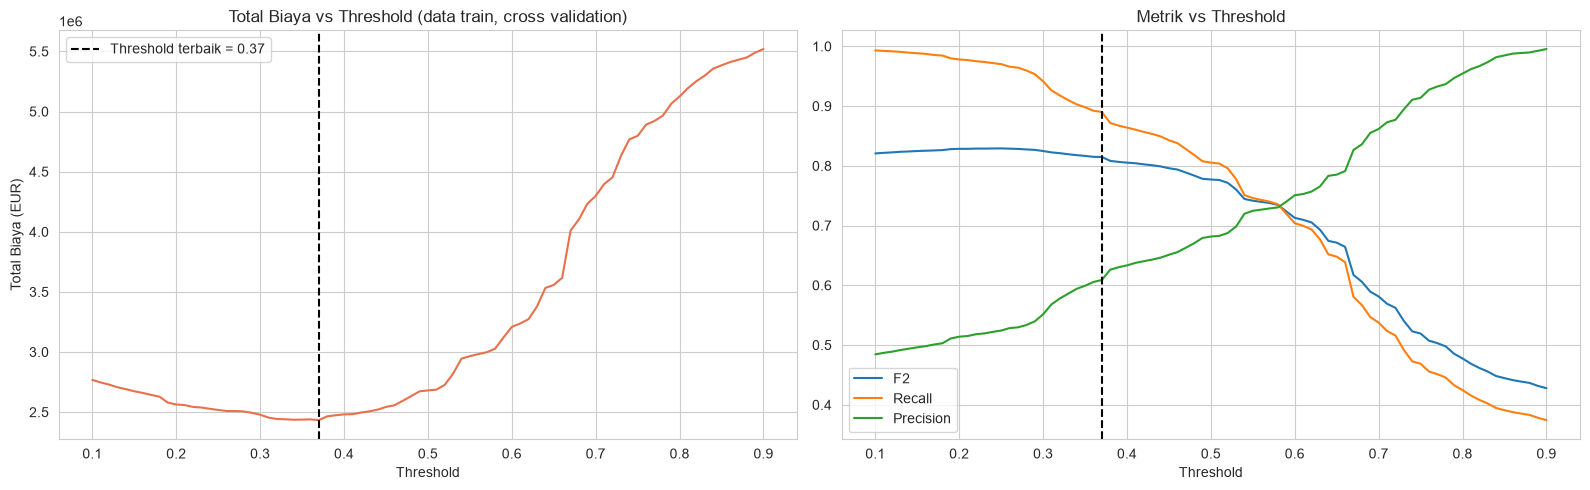

In [53]:
# Membuat grafik total biaya dan metrik terhadap threshold
fig, axes = plt.subplots(1, 2, figsize=(16, 5))  # membuat 2 grafik berdampingan

axes[0].plot(df_threshold["Threshold"], df_threshold["Total Biaya"], color="#E8704C")  # grafik total biaya
axes[0].axvline(best_threshold, color="black", linestyle="--", label="Threshold terbaik = " + str(best_threshold))  # garis threshold terbaik
axes[0].set_title("Total Biaya vs Threshold (data train, cross validation)")  # judul grafik
axes[0].set_xlabel("Threshold")  # label sumbu x
axes[0].set_ylabel("Total Biaya (EUR)")  # label sumbu y
axes[0].legend()  # menampilkan keterangan

for kolom in ["F2", "Recall", "Precision"]:  # perulangan untuk setiap metrik
    axes[1].plot(df_threshold["Threshold"], df_threshold[kolom], label=kolom)  # grafik metrik
axes[1].axvline(best_threshold, color="black", linestyle="--")  # garis threshold terbaik
axes[1].set_title("Metrik vs Threshold")  # judul grafik
axes[1].set_xlabel("Threshold")  # label sumbu x
axes[1].legend()  # menampilkan keterangan

plt.tight_layout()  # merapikan jarak antar grafik
plt.show()  # menampilkan grafik

**Insight threshold:**
- Total biaya paling rendah dicapai pada **threshold ±0,37**, bukan 0,5. Karena biaya FN ±3,4 kali biaya FP, lebih menguntungkan bagi hotel untuk "lebih waspada" dan menandai lebih banyak reservasi sebagai berisiko batal.
- Menurunkan threshold menaikkan recall (lebih banyak pembatalan terdeteksi) dengan konsekuensi precision turun (lebih banyak alarm palsu). Threshold 0,37 adalah titik keseimbangan dengan biaya terendah.
- Jika asumsi biaya berubah (misalnya biaya relokasi tamu ternyata lebih mahal), threshold ini perlu dihitung ulang dengan mengganti nilai `cost_fp` dan `cost_fn`.

# 8. Evaluation

## 8.1 Evaluasi Akhir pada Data Test

Kita membandingkan 5 skenario pada **data test** (data yang belum pernah dilihat model):
1. **Tanpa model: tidak pernah mengantisipasi pembatalan.** Semua reservasi dianggap datang, sehingga semua pembatalan menjadi FN.
2. **Tanpa model: menganggap semua reservasi batal.** Semua kamar di-*overbook*, sehingga semua tamu yang datang menjadi FP.
3. **Random Forest sebelum tuning** (threshold 0,5)
4. **Random Forest setelah tuning** (threshold 0,5)
5. **Random Forest setelah tuning + threshold optimal**

In [54]:
# Probabilitas batal pada data test dari model sebelum dan sesudah tuning
proba_base = rf_base.predict_proba(X_test)[:, 1]  # probabilitas dari model sebelum tuning
proba_tuned = rf_tuned.predict_proba(X_test)[:, 1]  # probabilitas dari model setelah tuning

# Fungsi untuk merangkum hasil evaluasi sebuah skenario
def evaluasi(nama, y_pred, y_proba=None):
    hasil = {
        "Skenario": nama,  # nama skenario
        "F2": fbeta_score(y_test, y_pred, beta=2),  # F2-score
        "Recall": recall_score(y_test, y_pred),  # recall
        "Precision": precision_score(y_test, y_pred, zero_division=0),  # precision
        "ROC AUC": roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan,  # ROC AUC (hanya untuk model)
        "PR AUC": average_precision_score(y_test, y_proba) if y_proba is not None else np.nan,  # PR AUC (hanya untuk model)
        "Total Biaya (EUR)": hitung_biaya(y_test, y_pred)  # total biaya
    }
    return hasil

# Menghitung hasil evaluasi untuk setiap skenario
hasil_test = [
    evaluasi("Tanpa model: semua dianggap datang", np.zeros(len(y_test), dtype=int)),
    evaluasi("Tanpa model: semua dianggap batal", np.ones(len(y_test), dtype=int)),
    evaluasi("RF sebelum tuning (threshold 0.5)", (proba_base >= 0.5).astype(int), proba_base),
    evaluasi("RF setelah tuning (threshold 0.5)", (proba_tuned >= 0.5).astype(int), proba_tuned),
    evaluasi("RF setelah tuning (threshold " + str(best_threshold) + ")", (proba_tuned >= best_threshold).astype(int), proba_tuned)
]

df_hasil_test = pd.DataFrame(hasil_test).round(4)
df_hasil_test

,Skenario,F2,Recall,Precision,ROC AUC,PR AUC,Total Biaya (EUR)
0,Tanpa model: semua dianggap datang,0.0000,0.0000,0.0000,NaN,NaN,2203848
1,Tanpa model: semua dianggap batal,0.7446,1.0000,0.3683,NaN,NaN,1098136
2,RF sebelum tuning (threshold 0.5),0.7693,0.7958,0.6787,0.8871,0.8409,691182
3,RF setelah tuning (threshold 0.5),0.7697,0.7961,0.6794,0.8882,0.8433,689842
4,RF setelah tuning (threshold 0.37),0.8135,0.8891,0.6072,0.8882,0.8433,612674


**Insight evaluasi data test:**
- **Model final** (RF tuning + threshold 0,37) mencapai **F2 = 0,814**, **Recall = 88,9%**, dan **Precision = 60,7%**. Semua target di Project Charter **tercapai** (F2 ≥ 0,75 dan recall ≥ 80%).
- **ROC AUC = 0,888** dan **PR AUC = 0,843** menunjukkan model mampu membedakan reservasi batal dan tidak batal dengan baik.
- Hasil data test **konsisten** dengan hasil cross validation (F2 CV pada threshold 0,37 = 0,815), sehingga model tidak overfitting terhadap data train.
- Tuning hyperparameter hampir tidak mengubah performa pada threshold 0,5. **Peningkatan terbesar datang dari threshold tuning**, yang menurunkan biaya sekitar EUR 78 ribu dibanding model sebelum tuning.
- Skenario "semua dianggap batal" memiliki F2 cukup tinggi (0,745) karena recall-nya 100%. Ini menunjukkan **F2 saja tidak cukup** untuk menilai model, sehingga metrik biaya tetap diperlukan: biaya skenario ini hampir 2 kali lipat biaya model.

                 precision    recall  f1-score   support

Tidak Batal (0)       0.91      0.66      0.77     10559
      Batal (1)       0.61      0.89      0.72      6156

       accuracy                           0.75     16715
      macro avg       0.76      0.78      0.75     16715
   weighted avg       0.80      0.75      0.75     16715



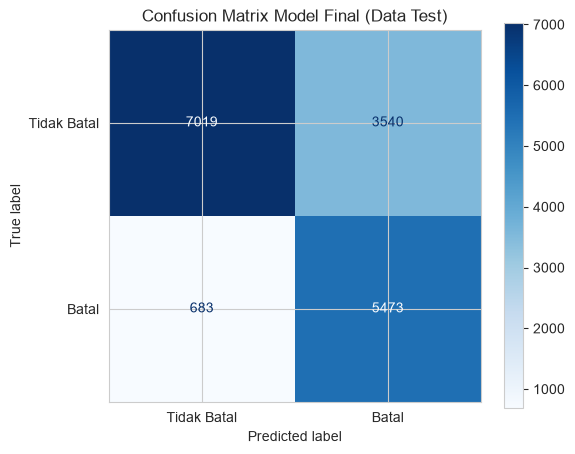

In [55]:
# Prediksi akhir model final memakai threshold optimal
y_pred_final = (proba_tuned >= best_threshold).astype(int)

# Menampilkan laporan klasifikasi
print(classification_report(y_test, y_pred_final, target_names=["Tidak Batal (0)", "Batal (1)"]))

# Menampilkan confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))  # ukuran grafik
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=["Tidak Batal", "Batal"], cmap="Blues", values_format="d", ax=ax)
plt.title("Confusion Matrix Model Final (Data Test)")  # judul grafik
plt.show()  # menampilkan grafik

**Cara membaca confusion matrix (data test, 16.715 booking):**
- **TP = 5.473**: pembatalan yang berhasil terdeteksi, sehingga kamar bisa diantisipasi lebih awal.
- **FN = 683**: pembatalan yang lolos dari deteksi (hanya ±11% dari semua pembatalan).
- **FP = 3.540**: reservasi yang diprediksi batal tetapi tamunya datang. Kelompok inilah alasan tindakan hotel harus **bertahap** (lihat rekomendasi), bukan langsung menjual ulang semua kamar.
- **TN = 7.019**: reservasi yang benar diprediksi datang.

In [56]:
# Menghitung penghematan biaya model final dibanding skenario tanpa model
biaya_model = df_hasil_test.iloc[4]["Total Biaya (EUR)"]  # biaya model final
biaya_tanpa_model = df_hasil_test.iloc[0]["Total Biaya (EUR)"]  # biaya jika semua dianggap datang
biaya_semua_batal = df_hasil_test.iloc[1]["Total Biaya (EUR)"]  # biaya jika semua dianggap batal
biaya_sebelum_tuning = df_hasil_test.iloc[2]["Total Biaya (EUR)"]  # biaya model sebelum tuning

print("Jumlah booking di data test                     :", len(y_test))
print("Biaya tanpa model (semua dianggap datang)       : EUR", f"{biaya_tanpa_model:,.0f}")
print("Biaya tanpa model (semua dianggap batal)        : EUR", f"{biaya_semua_batal:,.0f}")
print("Biaya model final                               : EUR", f"{biaya_model:,.0f}")
print("-" * 70)
print("Penghematan vs tidak mengantisipasi pembatalan  : EUR", f"{biaya_tanpa_model - biaya_model:,.0f}",
      "(", round((biaya_tanpa_model - biaya_model) / biaya_tanpa_model * 100, 1), "% )")
print("Penghematan vs model sebelum tuning             : EUR", f"{biaya_sebelum_tuning - biaya_model:,.0f}")
print("Rata-rata penghematan per booking               : EUR", round((biaya_tanpa_model - biaya_model) / len(y_test), 2))

Jumlah booking di data test                     : 16715
Biaya tanpa model (semua dianggap datang)       : EUR 2,203,848
Biaya tanpa model (semua dianggap batal)        : EUR 1,098,136
Biaya model final                               : EUR 612,674
----------------------------------------------------------------------
Penghematan vs tidak mengantisipasi pembatalan  : EUR 1,591,174 ( 72.2 % )
Penghematan vs model sebelum tuning             : EUR 78,508
Rata-rata penghematan per booking               : EUR 95.19


**Insight dampak bisnis (berdasarkan asumsi biaya):**
- Tanpa model, kerugian akibat pembatalan pada 16.715 booking di data test ≈ **EUR 2,20 juta**.
- Dengan model, total biaya turun menjadi ≈ **EUR 0,61 juta**, yaitu **hemat ≈ EUR 1,59 juta (±72%)** atau rata-rata **±EUR 95 per booking**.
- Dibanding strategi ekstrem "anggap semua batal", model juga **±44% lebih murah**.
- **Catatan:** perhitungan ini mengasumsikan setiap kamar dari pembatalan yang terdeteksi berhasil dijual ulang. Dalam praktiknya tidak semua kamar terjual ulang, sehingga angka ini adalah **batas atas** penghematan dan perlu divalidasi lewat uji coba (A/B test).

## 8.2 Kapan Model Bisa Dipercaya dan Kapan Tidak? (Analisis Error)

Kita melihat performa model di berbagai kelompok data pada data test untuk mengetahui **data seperti apa yang diprediksi dengan baik** dan **data seperti apa yang masih kurang akurat**.

In [57]:
# Menggabungkan data test dengan target asli dan hasil prediksi
df_eval = X_test.copy()  # menyalin data test
df_eval["aktual"] = y_test.values  # menambahkan target asli
df_eval["prediksi"] = y_pred_final  # menambahkan hasil prediksi
df_eval["proba"] = proba_tuned  # menambahkan probabilitas batal

# Fungsi untuk menghitung performa model per kelompok
def performa_per_grup(col):
    hasil = []  # list kosong untuk menampung hasil
    for nilai, grup in df_eval.groupby(col):  # perulangan untuk setiap kelompok
        if len(grup) < 100:  # kelompok yang terlalu kecil dilewati agar hasil tidak menyesatkan
            continue
        hasil.append([
            nilai,  # nama kelompok
            len(grup),  # jumlah data
            round(grup["aktual"].mean() * 100, 1),  # tingkat pembatalan aktual (%)
            round(recall_score(grup["aktual"], grup["prediksi"], zero_division=0), 3),  # recall
            round(precision_score(grup["aktual"], grup["prediksi"], zero_division=0), 3),  # precision
            round((grup["aktual"] == grup["prediksi"]).mean(), 3)  # akurasi
        ])
    return pd.DataFrame(hasil, columns=[col, "Jumlah", "Cancel Rate Aktual (%)", "Recall", "Precision", "Akurasi"])

# Menampilkan performa model per kelompok
for col in ["deposit_type", "market_segment", "customer_type", "is_domestic"]:
    display(performa_per_grup(col))

,deposit_type,Jumlah,Cancel Rate Aktual (%),Recall,Precision,Akurasi
0,No Deposit,14639,28.1,0.834,0.492,0.712
1,Non Refund,2046,99.5,1.000,0.997,0.997


,market_segment,Jumlah,Cancel Rate Aktual (%),Recall,Precision,Akurasi
0,Complementary,113,12.4,0.071,0.200,0.850
1,Corporate,768,17.6,0.704,0.446,0.794
2,Direct,1825,14.2,0.377,0.337,0.805
3,Groups,2779,61.4,0.994,0.884,0.916
4,Offline TA/TO,3420,34.0,0.970,0.713,0.857
5,Online TA,7774,36.9,0.854,0.491,0.619


,customer_type,Jumlah,Cancel Rate Aktual (%),Recall,Precision,Akurasi
0,Contract,530,33.2,0.994,0.841,0.936
1,Transient,12671,40.3,0.883,0.609,0.724
2,Transient-Party,3429,25.3,0.906,0.567,0.801


,is_domestic,Jumlah,Cancel Rate Aktual (%),Recall,Precision,Akurasi
0,0,9769,23.7,0.774,0.485,0.751
1,1,6946,55.3,0.958,0.692,0.742


**Insight: kapan model bisa dipercaya?**

| Kondisi | Performa | Kesimpulan |
|---|---|---|
| `deposit_type = Non Refund` | Recall 100%, precision 99,7% | **Sangat dapat dipercaya** |
| Segmen **Groups**, **Offline TA/TO**, tipe **Contract** | Recall ≥ 97%, akurasi 86–94% | **Dapat dipercaya** |
| Tamu domestik (Portugal) | Recall 96%, precision 69% | Cukup baik |
| Segmen **Online TA** (segmen terbesar) | Recall 85%, tetapi precision hanya 49% (akurasi 62%) | **Banyak alarm palsu**, perlu tindakan yang ringan (konfirmasi), bukan overbooking |
| Tamu dari **Western Europe** | Recall 55% | Kurang baik: tamu dari wilayah ini jarang batal (±19%) sehingga pembatalannya lebih sulit dideteksi |
| Segmen **Direct**, **Corporate**, **Complementary** | Recall hanya 7–70% | **Kurang dapat dipercaya**: pembatalan di segmen ini jarang (12–18%) dan sulit diprediksi dengan fitur yang ada |

In [58]:
# Melihat akurasi model berdasarkan tingkat keyakinan (probabilitas) prediksi
df_eval["kelompok_proba"] = pd.cut(df_eval["proba"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)  # membagi probabilitas ke 5 kelompok
tabel_proba = df_eval.groupby("kelompok_proba", observed=True).agg(
    Jumlah=("aktual", "size"),  # jumlah data di setiap kelompok
    Cancel_Rate_Aktual=("aktual", "mean")  # tingkat pembatalan aktual di setiap kelompok
)
tabel_proba["Cancel_Rate_Aktual"] = (tabel_proba["Cancel_Rate_Aktual"] * 100).round(1)  # mengubah ke persen
tabel_proba

,Jumlah,Cancel_Rate_Aktual
kelompok_proba,,
"(-0.001, 0.2]",5002,2.7
"(0.2, 0.4]",3308,22.0
"(0.4, 0.6]",2690,36.4
"(0.6, 0.8]",3025,57.1
"(0.8, 1.0]",2690,96.3


**Insight probabilitas:** probabilitas model cukup **sesuai dengan kenyataan**:
- Reservasi dengan probabilitas **> 0,8** benar-benar batal **±96%**, sedangkan probabilitas **≤ 0,2** hanya batal **±3%**. Di dua zona ini model sangat dapat dipercaya.
- Zona **0,4–0,6** adalah zona **ketidakpastian**: tingkat pembatalan aktualnya ±36%, sama dengan rata-rata keseluruhan. Prediksi pada zona ini sebaiknya tidak dipakai untuk keputusan berisiko tinggi seperti overbooking.
- Karena probabilitas cukup sesuai kenyataan, hotel bisa memakai **jumlah probabilitas** semua reservasi pada satu tanggal sebagai **perkiraan jumlah kamar yang akan batal** pada tanggal tersebut.

## 8.3 Seberapa Besar Limitasi Data Memengaruhi Model? (Eksperimen dengan `hotel_bookings.csv`)

Di EDA kita melihat bahwa *lead time* sangat memengaruhi pembatalan, tetapi tidak tersedia di dataset utama. Dataset pendukung `hotel_bookings.csv` memiliki kolom tersebut, sehingga kita bisa mengukur **berapa besar peningkatan performa jika hotel menambahkan fitur-fitur ini**.

Kita melatih **model dan preprocessing yang sama** (Random Forest, `class_weight="balanced"`) pada `hotel_bookings.csv` dengan 2 skenario:
1. **Fitur sama dengan model kita** (10 fitur final)
2. **Ditambah 6 fitur** yang tidak ada di dataset utama: `lead_time`, `arrival_date_month`, `hotel`, `adr`, lama menginap (`total_nights`), dan `adults`

Kolom yang berisi informasi setelah kejadian (`reservation_status`, `reservation_status_date`, `assigned_room_type`) **tidak dipakai** karena merupakan data leakage. Evaluasi memakai 3-fold cross validation agar lebih cepat.

In [59]:
# Menyiapkan data hotel_bookings untuk eksperimen
df_exp = df_hb[df_hb["market_segment"] != "Undefined"].copy()  # menghapus market_segment Undefined seperti di dataset utama
df_exp["is_domestic"] = (df_exp["country"] == "PRT").astype(int)  # membuat fitur is_domestic
df_exp["sub_region"] = df_exp["country"].map(peta_sub_region).fillna("Unknown")  # membuat fitur sub_region
df_exp["total_nights"] = df_exp["stays_in_weekend_nights"] + df_exp["stays_in_week_nights"]  # menghitung lama menginap

# Fitur tambahan yang tidak tersedia di dataset utama
tambahan_cat = ["hotel", "arrival_date_month"]  # fitur kategorikal tambahan
tambahan_num = ["lead_time", "total_nights", "adults", "adr"]  # fitur numerik tambahan

# Dua skenario fitur yang akan dibandingkan
skenario_fitur = {
    "Fitur sama dengan model kita": (cat_cols_final, num_cols_final),
    "Ditambah lead_time, adr, dll": (cat_cols_final + tambahan_cat, num_cols_final + tambahan_num)
}

skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # 3-fold cross validation
hasil_fitur = []  # list kosong untuk menampung hasil
for nama, (kolom_cat, kolom_num) in skenario_fitur.items():  # perulangan untuk setiap skenario
    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", cat_pipeline, kolom_cat),  # preprocessing kolom kategorikal
            ("num", RobustScaler(), kolom_num)  # preprocessing kolom numerik
        ])),
        ("model", RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1))
    ])
    skor_f2 = cross_val_score(pipe, df_exp, df_exp["is_canceled"], cv=skf3, scoring=f2_scorer, n_jobs=-1)  # F2-score
    skor_auc = cross_val_score(pipe, df_exp, df_exp["is_canceled"], cv=skf3, scoring="roc_auc", n_jobs=-1)  # ROC AUC
    hasil_fitur.append([nama, len(kolom_cat) + len(kolom_num), skor_f2.mean(), skor_auc.mean()])  # menyimpan hasil

df_hasil_fitur = pd.DataFrame(hasil_fitur, columns=["Skenario", "Jumlah Fitur", "Mean F2", "Mean ROC AUC"])
df_hasil_fitur

,Skenario,Jumlah Fitur,Mean F2,Mean ROC AUC
0,Fitur sama dengan model kita,10,0.776529,0.888553
1,"Ditambah lead_time, adr, dll",16,0.825128,0.942723


**Insight:**
- Dengan fitur yang sama, model di `hotel_bookings.csv` menghasilkan skor yang **hampir sama** dengan model kita. Ini membuktikan pipeline kita **konsisten** dan tidak overfitting pada dataset utama.
- Dengan menambah *lead time*, bulan kedatangan, harga, dan lama menginap, performa **naik signifikan**: F2 naik ±0,05 dan ROC AUC naik dari ±0,89 menjadi ±0,94.
- Artinya, **batas performa model kita berasal dari data yang tersedia, bukan dari algoritma**. Rekomendasi paling berdampak untuk pengembangan model adalah **menambahkan data *lead time*, tanggal kedatangan, dan harga** dari PMS hotel.

# 9. Model Explanation

**Goal:** hasil prediksi model bisa dijelaskan, sehingga stakeholder memahami **faktor apa yang membuat sebuah reservasi diprediksi batal**.

## 9.1 Feature Importance (Random Forest)

*Feature importance* bawaan Random Forest mengukur seberapa besar setiap fitur membantu mengurangi "ketidakmurnian" (*impurity*) saat membuat percabangan di semua pohon.

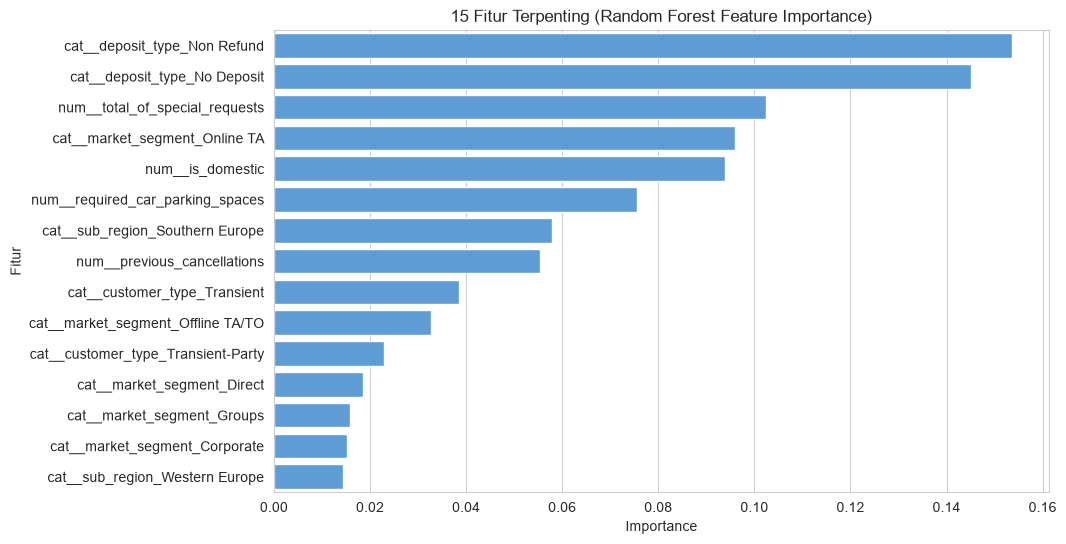

In [60]:
# Mengambil nama fitur setelah preprocessing dan nilai feature importance dari model final
nama_fitur = rf_tuned.named_steps["prep"].get_feature_names_out()  # nama fitur hasil one-hot encoding
importance = rf_tuned.named_steps["model"].feature_importances_  # nilai kepentingan setiap fitur

# Membuat DataFrame feature importance dan mengambil 15 fitur teratas
df_importance = pd.DataFrame({"Fitur": nama_fitur, "Importance": importance})
df_importance = df_importance.sort_values("Importance", ascending=False).head(15)

# Membuat grafik feature importance
plt.figure(figsize=(10, 6))  # ukuran grafik
sns.barplot(x="Importance", y="Fitur", data=df_importance, color="#4C9BE8")  # grafik batang horizontal
plt.title("15 Fitur Terpenting (Random Forest Feature Importance)")  # judul grafik
plt.show()  # menampilkan grafik

**Insight:** fitur `deposit_type` (Non Refund dan No Deposit) adalah yang paling penting, diikuti `total_of_special_requests`, `market_segment = Online TA`, `is_domestic`, `required_car_parking_spaces`, dan `sub_region = Southern Europe`.

## 9.2 Permutation Importance (pada Data Test)

*Permutation importance* mengukur **seberapa besar performa model turun jika nilai satu fitur diacak**. Semakin besar penurunannya, semakin penting fitur tersebut. Metode ini dihitung pada **data test** dan pada **kolom asli** (sebelum one-hot encoding), sehingga lebih mudah dipahami stakeholder. Metrik yang dipakai adalah ROC AUC karena tidak bergantung pada threshold.

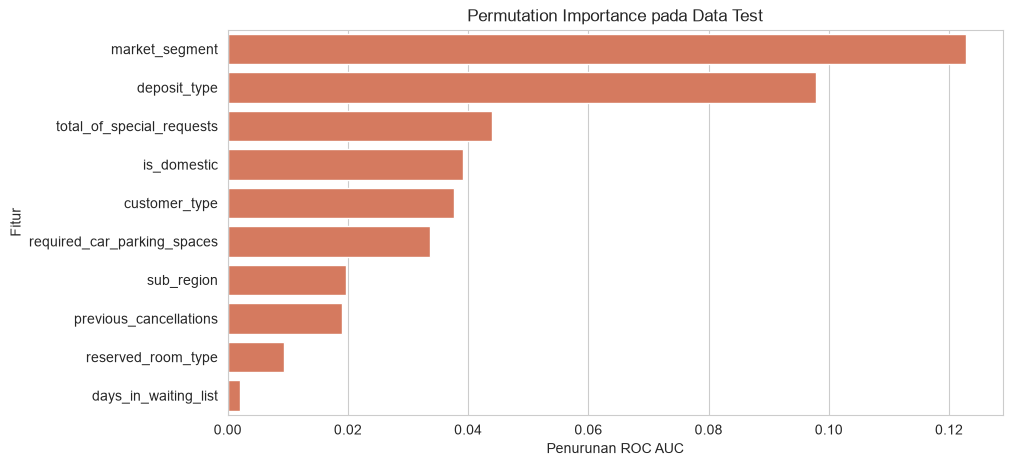

,Fitur,Penurunan ROC AUC,Std
0,market_segment,0.122788,0.000994
1,deposit_type,0.097876,0.001255
8,total_of_special_requests,0.043912,0.000832
9,is_domestic,0.039075,0.001181
2,customer_type,0.037561,0.001637
7,required_car_parking_spaces,0.033684,0.001437
4,sub_region,0.019684,0.000872
5,previous_cancellations,0.018952,0.000629
3,reserved_room_type,0.009354,0.000500
6,days_in_waiting_list,0.001997,0.000115


In [61]:
# Menghitung permutation importance pada data test
perm = permutation_importance(rf_tuned, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)

# Membuat DataFrame hasil permutation importance
df_perm = pd.DataFrame({
    "Fitur": X_test.columns,  # nama kolom asli
    "Penurunan ROC AUC": perm.importances_mean,  # rata-rata penurunan performa
    "Std": perm.importances_std  # standar deviasi penurunan performa
}).sort_values("Penurunan ROC AUC", ascending=False)

# Membuat grafik permutation importance
plt.figure(figsize=(10, 5))  # ukuran grafik
sns.barplot(x="Penurunan ROC AUC", y="Fitur", data=df_perm, color="#E8704C")  # grafik batang horizontal
plt.title("Permutation Importance pada Data Test")  # judul grafik
plt.show()  # menampilkan grafik
df_perm

**Insight permutation importance:**
1. **`market_segment`** dan **`deposit_type`** adalah dua faktor paling penting. Jika informasinya diacak, ROC AUC turun ±0,10–0,12.
2. Faktor berikutnya adalah **`total_of_special_requests`**, **`is_domestic`**, **`customer_type`**, dan **`required_car_parking_spaces`**, diikuti **`sub_region`** dan **`previous_cancellations`**.
3. **`days_in_waiting_list`** dan **`reserved_room_type`** hampir tidak berpengaruh.

Hasil ini **konsisten dengan EDA**: saluran pemesanan, kebijakan deposit, dan tingkat komitmen tamu (permintaan khusus, parkir) adalah penentu utama pembatalan.

## 9.3 SHAP (SHapley Additive exPlanations)

SHAP menjelaskan **arah dan besar pengaruh** setiap fitur terhadap prediksi:
- titik **merah** = nilai fitur tinggi, titik **biru** = nilai fitur rendah
- titik di **kanan** (SHAP > 0) = mendorong prediksi ke arah **batal**
- titik di **kiri** (SHAP < 0) = mendorong prediksi ke arah **tidak batal**

Library `shap` sudah tersedia di Google Colab. Jika dijalankan di komputer sendiri dan belum terpasang, jalankan `pip install shap` terlebih dahulu.

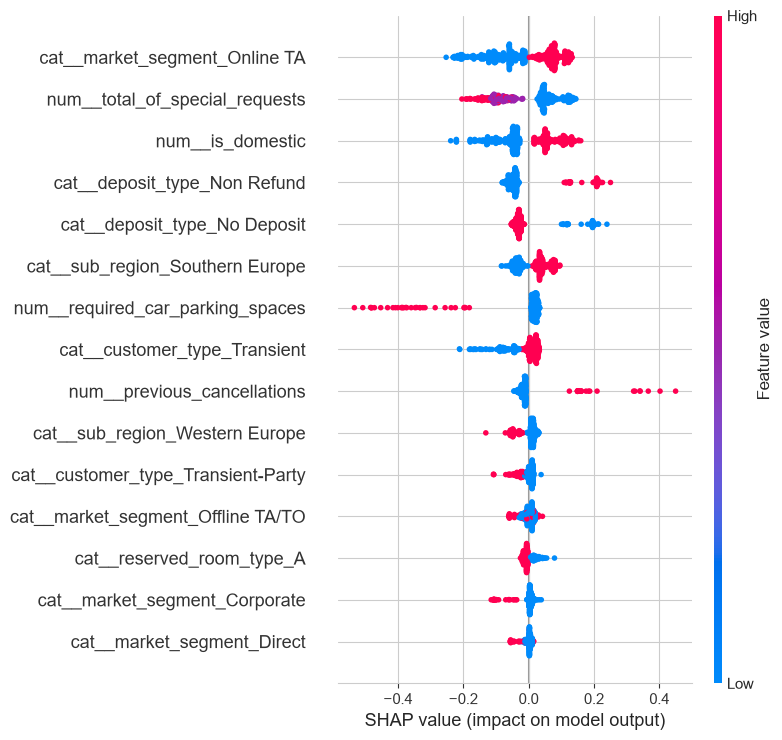

In [62]:
try:
    import shap  # library untuk model explanation

    # Mengambil 500 sampel data test agar perhitungan SHAP tidak terlalu lama
    X_sample = X_test.sample(500, random_state=42)
    X_sample_prep = rf_tuned.named_steps["prep"].transform(X_sample)  # preprocessing sampel data

    # Membuat explainer khusus model berbasis pohon
    explainer = shap.TreeExplainer(rf_tuned.named_steps["model"])
    shap_values = explainer.shap_values(X_sample_prep)  # menghitung nilai SHAP

    # Mengambil nilai SHAP untuk kelas 1 (batal), bentuk output berbeda tergantung versi shap
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif len(np.shape(shap_values)) == 3:
        shap_values = shap_values[:, :, 1]

    # Menampilkan SHAP summary plot untuk 15 fitur teratas
    shap.summary_plot(shap_values, X_sample_prep, feature_names=nama_fitur, max_display=15)
except ImportError:
    print("Library shap belum terpasang. Jalankan: pip install shap, lalu jalankan ulang sel ini.")

**Cara membaca SHAP summary plot untuk model ini** (konsisten dengan EDA dan feature importance):
- `deposit_type_Non Refund` bernilai 1 (merah) mendorong prediksi kuat ke arah **batal**.
- `total_of_special_requests` dan `required_car_parking_spaces` yang tinggi (merah) mendorong prediksi ke arah **tidak batal**, karena keduanya menunjukkan tamu yang berkomitmen.
- `is_domestic` = 1, `sub_region_Southern Europe` = 1, dan `market_segment_Online TA` = 1 mendorong prediksi ke arah **batal**.
- `previous_cancellations` yang tinggi mendorong prediksi ke arah **batal**, karena tamu dengan riwayat membatalkan cenderung mengulanginya.

# 10. Conclusion & Recommendation

## 10.1 Conclusion

**1. Solusi yang dibuat.** Model **Random Forest** (hasil tuning, `class_weight="balanced"`, threshold 0,37) dengan 10 fitur reservasi untuk memprediksi apakah sebuah reservasi akan dibatalkan. Tiga dataset pendukung dari Kaggle dipakai untuk memperkuat analisis:

| Dataset pendukung | Kontribusi |
|---|---|
| `hotel_bookings.csv` | Dasar perhitungan biaya (ADR €103,53 × 3,46 malam), serta bukti bahwa batas performa model berasal dari fitur yang tidak tersedia |
| `Hotel Reservations.csv` | Validasi bahwa pola komitmen tamu dan saluran pemesanan juga berlaku di hotel lain |
| `continents2.csv` | Feature engineering `sub_region` yang menggantikan `country` (162 kategori) tanpa menurunkan performa |

**2. Pencapaian terhadap target (data test, 16.715 booking):**

| Metrik | Target (Project Charter) | Hasil | Status |
|---|---|---|---|
| F2-score | ≥ 0,75 | **0,814** | ✅ Tercapai |
| Recall kelas batal | ≥ 80% | **88,9%** | ✅ Tercapai |
| Total biaya vs tanpa model | Lebih rendah | **EUR 0,61 juta vs EUR 2,20 juta (−72%)** | ✅ Tercapai |
| ROC AUC / PR AUC | – | 0,888 / 0,843 | Baik |

**3. Cara kerja model dan faktor utama pembatalan.** Model mendeteksi **±89% dari semua pembatalan**. Dari setiap 10 reservasi yang ditandai berisiko, ±6 benar-benar batal. Faktor terpenting:
- **Saluran pemesanan (`market_segment`)**: Groups dan Online TA paling sering batal, sedangkan Direct dan Corporate paling stabil. Pola Online vs Corporate juga terlihat di hotel lain.
- **Kebijakan deposit (`deposit_type`)**: reservasi Non Refund hampir selalu batal (±99%).
- **Komitmen tamu**: permintaan khusus dan permintaan parkir menurunkan peluang batal secara tajam. Pola ini **terbukti juga terjadi di hotel lain**.
- **Asal tamu**: tamu domestik (Portugal) dan tamu dari Southern Europe jauh lebih sering batal (±50–56%) dibanding tamu dari Western/Northern Europe (±19–21%).
- **Riwayat tamu**: tamu yang pernah membatalkan cenderung membatalkan lagi. Pola ini **khusus untuk hotel ini** dan tidak terlihat di hotel lain.

**4. Dampak terhadap proses bisnis (berdasarkan asumsi biaya dari dataset pendukung).** Model berpotensi menghemat **±EUR 95 per booking**, atau ±EUR 1,59 juta pada 16.715 booking data test. Angka ini adalah batas atas karena mengasumsikan kamar yang terdeteksi batal berhasil dijual ulang.

**5. Kapan model bisa dipercaya dan kapan tidak:**
- ✅ **Dapat dipercaya:** reservasi Non Refund, segmen Groups, Offline TA/TO, tipe Contract, dan semua prediksi dengan probabilitas sangat tinggi (> 0,8, ±96% benar batal) atau sangat rendah (≤ 0,2, hanya ±3% batal).
- ⚠️ **Kurang dapat dipercaya:** segmen Direct, Corporate, dan Complementary (recall rendah), tamu dari Western Europe (recall 55%), segmen Online TA (banyak alarm palsu, precision ±49%), serta prediksi dengan probabilitas 0,4–0,6.

**6. Limitasi project:**
- **Data:** dataset utama tidak memiliki *lead time*, tanggal kedatangan, harga, lama menginap, dan jumlah tamu. Eksperimen dengan `hotel_bookings.csv` membuktikan bahwa fitur-fitur ini bisa menaikkan ROC AUC dari ±0,89 menjadi ±0,94. Jadi **batas performa model berasal dari data, bukan dari algoritma**.
- **Data:** data hanya berasal dari hotel di Portugal pada periode tertentu. Validasi dengan hotel lain menunjukkan sebagian besar pola berlaku umum, tetapi pola riwayat pembatalan tidak. Model perlu diuji ulang sebelum dipakai di hotel lain.
- **Asumsi:** `required_car_parking_spaces` diasumsikan tercatat saat reservasi dibuat. Di hotel lain, tamu yang meminta parkir masih batal ±10%, bukan 0%, sehingga asumsi ini perlu dikonfirmasi. Biaya FP (EUR 104) dan FN (EUR 358) dihitung dari rata-rata ADR dan lama menginap di dataset pendukung, bukan dari data keuangan hotel yang sebenarnya.
- **Model:** hyperparameter tuning memberi peningkatan yang sangat kecil, sehingga peningkatan performa ke depan lebih bergantung pada penambahan fitur daripada pergantian algoritma.

## 10.2 Recommendation

### Rekomendasi Bisnis (cara memakai model)

1. **Gunakan tindakan bertahap berdasarkan probabilitas**, bukan satu aturan untuk semua:

   | Probabilitas batal | Tindakan yang disarankan |
   |---|---|
   | **> 0,8** (±96% benar batal) | Kamar boleh dimasukkan ke kuota **overbooking / dijual ulang** |
   | **0,37 – 0,8** | **Konfirmasi ulang** ke tamu (email/WhatsApp H-7), tawarkan fasilitas tambahan agar tamu tetap datang. **Jangan langsung di-overbook** |
   | **< 0,37** | Diperlakukan normal |

2. **Overbooking per tanggal memakai jumlah probabilitas.** Karena probabilitas model cukup sesuai kenyataan, perkiraan jumlah kamar yang akan batal pada suatu tanggal adalah jumlah probabilitas semua reservasi di tanggal tersebut. Lakukan overbooking **sedikit di bawah** angka tersebut sebagai margin aman.
3. **Tinjau ulang kerja sama dengan agen/grup yang memakai deposit Non Refund.** ±99% reservasi ini batal. Meskipun uang deposit masuk, kamar tetap kosong dan peluang menjual ke tamu lain hilang. Hotel bisa menerapkan **release date** (kamar dilepas otomatis jika tidak dikonfirmasi) atau membatasi kuota blok kamar.
4. **Kurangi risiko dari segmen Online TA dan tamu domestik/Southern Europe**, misalnya dengan deposit sebagian, pengingat konfirmasi, atau insentif untuk **booking langsung (Direct)**. Segmen Direct hanya batal ±14%.
5. **Dorong keterlibatan tamu sebelum kedatangan**, misalnya menawarkan pilihan kamar, parkir, atau permintaan khusus melalui email pra-kedatangan. Pola "tamu yang berinteraksi jarang batal" terlihat di dua hotel berbeda. *(Catatan: ini hubungan korelasi, sehingga efeknya perlu diuji dengan A/B test.)*
6. **Perhatikan reservasi yang dibuat jauh hari.** Data pendukung menunjukkan reservasi dengan *lead time* > 6 bulan batal ±55–95%. Selama fitur ini belum masuk model, tim reservasi bisa menambahkan aturan konfirmasi ulang untuk reservasi jangka panjang.
7. **Uji coba bertahap (A/B test)** sebelum dipakai penuh: misalnya model dipakai untuk 50% tanggal, lalu bandingkan okupansi dan biaya relokasi tamu dengan 50% tanggal lainnya.

### Rekomendasi Pengembangan Model

1. **Tambahkan fitur `lead_time`, bulan kedatangan, `adr`, lama menginap, dan jumlah tamu** dari PMS hotel. Eksperimen dengan `hotel_bookings.csv` menunjukkan ini adalah langkah dengan **dampak terbesar** (F2 ±0,78 → ±0,83, ROC AUC ±0,89 → ±0,94).
2. **Konfirmasi waktu pencatatan fitur** `required_car_parking_spaces` ke tim PMS untuk memastikan tidak ada data leakage.
3. **Ganti asumsi biaya** `cost_fp` dan `cost_fn` dengan data keuangan hotel yang sebenarnya, lalu hitung ulang threshold optimal.
4. **Coba algoritma boosting lain** (XGBoost, LightGBM, CatBoost) dan **kalibrasi probabilitas** setelah fitur baru ditambahkan.
5. **Monitoring dan retraining:** pantau recall dan precision setiap bulan, dan latih ulang model setiap kuartal karena pola pembatalan bersifat musiman.

# 11. Save Model

Model final beserta threshold dan daftar fiturnya disimpan ke file `.pkl` agar bisa dipakai kembali tanpa melatih ulang.

In [63]:
# Menyimpan model final, threshold, dan daftar fitur ke dalam satu file
paket_model = {
    "model": rf_tuned,  # pipeline model final (preprocessing + Random Forest)
    "threshold": best_threshold,  # threshold optimal hasil threshold tuning
    "fitur": fitur_final,  # daftar fitur yang dibutuhkan model
    "peta_sub_region": peta_sub_region  # kamus kode negara -> sub-region untuk membuat fitur sub_region
}

with open("model_hotel_cancellation.pkl", "wb") as file:  # membuka file untuk ditulis dalam mode biner
    pickle.dump(paket_model, file)  # menyimpan paket model ke file

print("Model berhasil disimpan ke model_hotel_cancellation.pkl")

Model berhasil disimpan ke model_hotel_cancellation.pkl


In [64]:
# Membaca kembali model dari file
with open("model_hotel_cancellation.pkl", "rb") as file:  # membuka file untuk dibaca dalam mode biner
    paket = pickle.load(file)  # memuat paket model

# Contoh data reservasi baru
booking_baru = pd.DataFrame({
    "country": ["PRT", "GBR"],  # negara asal tamu
    "market_segment": ["Online TA", "Direct"],  # segmen pasar
    "deposit_type": ["No Deposit", "No Deposit"],  # jenis deposit
    "customer_type": ["Transient", "Transient"],  # jenis tamu
    "reserved_room_type": ["A", "D"],  # tipe kamar
    "previous_cancellations": [1, 0],  # jumlah pembatalan sebelumnya
    "days_in_waiting_list": [0, 0],  # lama di daftar tunggu
    "required_car_parking_spaces": [0, 1],  # jumlah parkir yang diminta
    "total_of_special_requests": [0, 2]  # jumlah permintaan khusus
})

# Membuat fitur is_domestic dan sub_region seperti saat training
booking_baru["is_domestic"] = (booking_baru["country"] == "PRT").astype(int)
booking_baru["sub_region"] = booking_baru["country"].map(paket["peta_sub_region"]).fillna("Unknown")

# Memprediksi probabilitas batal dan label akhir memakai threshold optimal
booking_baru["probabilitas_batal"] = paket["model"].predict_proba(booking_baru[paket["fitur"]])[:, 1].round(3)
booking_baru["prediksi"] = np.where(booking_baru["probabilitas_batal"] >= paket["threshold"], "Berisiko Batal", "Aman")
booking_baru

,country,market_segment,deposit_type,customer_type,reserved_room_type,previous_cancellations,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_domestic,sub_region,probabilitas_batal,prediksi
0,PRT,Online TA,No Deposit,Transient,A,1,0,0,0,1,Southern Europe,0.988,Berisiko Batal
1,GBR,Direct,No Deposit,Transient,D,0,0,1,2,0,Northern Europe,0.001,Aman
